# Data and materials: every data fact of the thesis, rebuilt from source

This notebook rebuilds every number the thesis reports about its **data** directly from the original files, checks each one against an expected value, and writes the results to `results/data/`.

**Inputs (the only files read):**

| Source | What it gives us |
|---|---|
| Zenodo release of Hojjati et al. (2026), DOI 10.5281/zenodo.17642106, v1 | similarity trials and human rankings, model embeddings, recognition pairs, released alignment scores, cross-validation splits |
| Bainbridge et al. (2013), 10k US Adult Faces (USAFD) | per-rater social-trait ratings, demographic labels, memorability scores for 2,222 faces |
| Chicago Face Database 3.0.1 norming data and codebook (Ma, Correll & Wittenbrink, 2015) | identities, self-reported race and gender, trait norms for the 597 CFD faces |

**Key terms used throughout**

- **Face id**: one integer per face. USAFD faces are ids 1–2,222 (id *i* = line *i* of `target-filenames.txt`); CFD faces are ids 2,223–2,819. Arrays in the Zenodo release use 0-based ids (id − 1).
- **Similarity trial**: one reference face plus 4 candidate faces that human participants ranked by similarity to the reference.
- **Main set**: USAFD faces that appear in at least one similarity trial (1,678). **Hold-out set**: USAFD faces that appear in no trial (544). **Hojjati set**: main + CFD (2,275).
- **Alignment**: how well a model's distances reproduce the human ranking of the 4 candidates (mean per-trial Spearman ρ; 0 = chance, 1 = identical ranking).

**Outputs:** CSV tables in `results/data/` and figures in `results/data/figures/`.

## 0. Configuration and environment

Paths, the random seed, face counts, a shared plotting style, and the model-family colours used in every figure. `save(fig, name)` writes each figure to `results/data/figures/`.

In [1]:
import sys, os, json, hashlib, platform, pickle
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import chi2_contingency
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
import re

REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
ZEN = os.path.join(REPO, "datasets", "external", "hojjati_zenodo")
RAW = os.path.join(REPO, "datasets", "raw")
CFD_NORMS = os.path.join(REPO, "datasets", "raw", "cfd", "CFD 3.0.1 Norming Data and Codebook.xlsx")
OUT = os.path.join(REPO, "results", "data")
os.makedirs(OUT, exist_ok=True)

SEED = 1
rng = np.random.default_rng(SEED)
N_USAFD, N_CFD = 2222, 597
N_TOTAL = N_USAFD + N_CFD

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()

def _walk(base, *parts):
    return os.path.join(base, *parts)

# ---- plotting style and figure output ----
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = os.path.join(OUT, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
SAVE_FIGS = True

def save(fig, name):
    """Save a figure to results/data/figures/<name>.png."""
    if SAVE_FIGS:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

# model families: variants of one architecture share a colour in every figure
FAMILY = {"ArcFace18": "ArcFace", "ArcFace34": "ArcFace", "ArcFace50": "ArcFace", "ArcFace100": "ArcFace",
          "swinface": "SwinFace", "FaceNet": "FaceNet", "FaceNet512": "FaceNet", "Dlib": "Dlib",
          "VGG-Face": "VGG-Face", "GhostFaceNet": "GhostFaceNet", "SFace": "SFace",
          "DeepFace": "DeepFace", "OpenFace": "OpenFace", "DeepID": "DeepID",
          "AAM": "Non-recognition", "StyleGAN2": "Non-recognition"}
_fams = list(dict.fromkeys(f for f in FAMILY.values() if f != "Non-recognition"))
_pal = [c for i, c in enumerate(sns.color_palette("tab10", 10)) if i != 7] + [(0.22, 0.23, 0.47)]   # no grey
FAMILY_COLORS = dict(zip(_fams, _pal))
FAMILY_COLORS["Non-recognition"] = (0.55, 0.55, 0.55)
SET_COLORS = {"main": "#4C72B0", "holdout": "#DD8452", "cfd": "#8172B3"}

print("repo:", REPO)
print("python:", platform.python_version())
print("seed:", SEED)
print("outputs dir:", OUT)
print("figures dir:", FIG_DIR)


repo: /home/muhammad/Papers/Human alignment of face recognition models in facial social impressions 2
python: 3.11.18
seed: 1
outputs dir: /home/muhammad/Papers/Human alignment of face recognition models in facial social impressions 2/results/data
figures dir: /home/muhammad/Papers/Human alignment of face recognition models in facial social impressions 2/results/data/figures


## 1. Inventory of input files

Lists every input file with its size and SHA-256 hash and writes `inventory.csv`.

In [2]:
# ============================================================ 1. Inventory
# Zenodo release of Hojjati et al. (2026): DOI 10.5281/zenodo.17642106,
# version 1.  Inputs below are the ONLY files this notebook reads.
ZENODO_DOI = "10.5281/zenodo.17642106"
ZENODO_VERSION = 1

inputs = {
    "zenodo": [
        (ZEN, "Split_data", "All_Similarity_trials.npy"),
        (ZEN, "Split_data", "All_Similarity_scores.npy"),
        (ZEN, "Split_data", "USAFD_Similarity_trials.npy"),
        (ZEN, "Split_data", "USAFD_Similarity_scores.npy"),
        (ZEN, "Split_data", "CFD_Similarity_trials.npy"),
        (ZEN, "Split_data", "CFD_Similarity_scores.npy"),
        (ZEN, "Recognition_task_pairs", "positive_pairs.npy"),
        (ZEN, "Recognition_task_pairs", "negative_pairs.npy"),
        (ZEN, "Models_alignment.pkl"),
        (ZEN, "Trained_Ws_PCs", "Note.txt"),
    ],
    "bainbridge": [
        (RAW, "2kattributes", "target-filenames.txt"),
        (RAW, "2kattributes", "demographic & others labels", "demographic-others-labels.xlsx"),
        (RAW, "2kattributes", "psychology attributes", "psychology-attributes.xlsx"),
        (RAW, "2kmemorability", "memorability-scores.xlsx"),
        (RAW, "2kmemorability", "target-filenames.txt"),
    ],
    "cfd": [
        (CFD_NORMS,),
    ],
}

inv_rows, missing = [], []
for group, items in inputs.items():
    for item in items:
        p = _walk(*item)
        if not os.path.exists(p):
            missing.append(p)
            continue
        sz = os.path.getsize(p)
        inv_rows.append(dict(group=group, path=os.path.relpath(p, REPO),
                             bytes=sz, sha256=sha256(p)))
inventory = pd.DataFrame(inv_rows)
inventory.to_csv(os.path.join(OUT, "inventory.csv"), index=False)
print(inventory.to_string(index=False))
print("\nmissing inputs:", missing if missing else "none")


     group                                                                                 path   bytes                                                           sha256
    zenodo                datasets/external/hojjati_zenodo/Split_data/All_Similarity_trials.npy 1338728 bcd3c322550cc55f3c04e8b152bc5d52232c2ae9ae97a40ea5032ba4a4b325c9
    zenodo                datasets/external/hojjati_zenodo/Split_data/All_Similarity_scores.npy 1338728 f9e5143a16246a389391bbb6fd47f98deee0b48ed0b29fd82cf02555b52ab762
    zenodo              datasets/external/hojjati_zenodo/Split_data/USAFD_Similarity_trials.npy  910128 dba968ceb1549fb29387efdcae9b493f8e9075861948ac2163290070b5c51d64
    zenodo              datasets/external/hojjati_zenodo/Split_data/USAFD_Similarity_scores.npy  910128 3ce48c2c372ad92166f27baccc826df72188737df09385f82552556749fde59a
    zenodo                datasets/external/hojjati_zenodo/Split_data/CFD_Similarity_trials.npy  289208 81da6db707fcdd55cc2ba1c017dbf494eb63c5fc77f60127bc5

### 1b. File contents

Shape, data type and value range of each array, the keys of each pickle, and the sheets of each workbook.

In [3]:
# ---- Zenodo arrays and pickles: type, shape, dtype / keys
def _describe(p):
    if p.endswith(".npy"):
        a = np.load(p, allow_pickle=True)
        info = dict(kind="npy", shape=list(a.shape), dtype=str(a.dtype))
        if np.issubdtype(a.dtype, np.number):
            info["min"] = float(a.min()); info["max"] = float(a.max())
        else:
            info["min"] = None; info["max"] = None
        return info
    if p.endswith(".pkl"):
        with open(p, "rb") as fh:
            d = pickle.load(fh)
        if isinstance(d, dict):
            first_val = next(iter(d.values()), None)
            return dict(kind="pkl-dict", keys=len(d),
                        sample_keys=list(d.keys())[:3],
                        sample_val_shape=(list(np.asarray(first_val).shape)
                                          if first_val is not None else None))
        return dict(kind="pkl", type=type(d).__name__)
    if p.endswith(".txt"):
        with open(p) as fh:
            lines = fh.read().splitlines()
        return dict(kind="txt", lines=len(lines),
                    first=lines[0] if lines else None)
    if p.endswith(".xlsx"):
        xl = pd.ExcelFile(p)
        return dict(kind="xlsx", sheets=xl.sheet_names)
    return dict(kind=os.path.splitext(p)[1])

desc_rows = []
for _, row in inventory.iterrows():
    p = os.path.join(REPO, row["path"])
    d = _describe(p)
    desc_rows.append(dict(path=row["path"], **d))
desc = pd.DataFrame(desc_rows)
print(desc.to_string(index=False))

# Note.txt
note_path = _walk(ZEN, "Trained_Ws_PCs", "Note.txt")
with open(note_path) as fh:
    note = fh.read()
print("\n--- Trained_Ws_PCs/Note.txt ---")
print(note)

                                                                                path     kind      shape   dtype    min    max  keys                                                     sample_keys sample_val_shape  lines                                                                                                                                                                                                                                                                                                                                                                                                                             first                                                                                                                 sheets
               datasets/external/hojjati_zenodo/Split_data/All_Similarity_trials.npy      npy [33465, 5]   int64    0.0 2818.0   NaN                                                             NaN              NaN    NaN                      

## 2. Face IDs and row order

row *k* of every embedding array is face id *k* + 1:

- `target-filenames.txt` has 2,222 lines (USAFD ids 1–2,222);
- all 16 similarity-task embedding files have exactly 2,819 rows (2,222 USAFD + 597 CFD);
- all 14 recognition-task embedding pickles hold the same 1,207 CFD images;
- trial arrays use 0-based ids (maximum 2,818).

In [4]:
# ============================================================ 2. IDs and row order
# ID scheme: USAFD ids 1..2,222 (id i = line i of target-filenames.txt),
# CFD ids 2,223..2,819.  The CFD id mapping is in the release:
# external/hojjati_code/FaceIDs_to_CFD_correspondence.csv (id -> CFD filename).
try:
    corr = pd.read_csv(_walk(ZEN, "FaceIDs_to_CFD_correspondence.csv"))
except FileNotFoundError:
    corr = pd.DataFrame()
# The correspondence file is not in this repo's Zenodo folder; the CFD id
# mapping is instead derived from the norming workbook "Model" column (cell 5).
corr = None

# target-filenames.txt: line i -> USAFD id i
tf = pd.read_csv(_walk(RAW, "2kattributes", "target-filenames.txt"),
                 header=None, names=["id", "filename"])
tf["filename"] = tf["filename"].astype(str).str.strip()
print("target-filenames.txt rows:", len(tf), "ids", tf["id"].min(), "..", tf["id"].max())

# ---- embedding row order: every array must have 2,819 rows in id order ----
emb_dir = _walk(ZEN, "Similarity_task_images_embeds")
emb_files = sorted(f for f in os.listdir(emb_dir) if f.endswith(".npy"))
emb_ok = True
for f in emb_files:
    a = np.load(os.path.join(emb_dir, f))
    if a.shape[0] != N_TOTAL:
        emb_ok = False
        print(f"  {f}: shape {a.shape} != ({N_TOTAL}, d)")
print(f"similarity embeddings: {len(emb_files)} files, all {N_TOTAL} rows = {emb_ok}")

recog_dir = _walk(ZEN, "Recognition_task_images_embeds")
recog_pkls = sorted(f for f in os.listdir(recog_dir) if f.endswith("_embs.pkl"))
recog_ok = True
for f in recog_pkls:
    with open(os.path.join(recog_dir, f), "rb") as fh:
        d = pickle.load(fh)
    if len(d) != 1207:
        recog_ok = False
        print(f"  {f}: {len(d)} entries != 1207")
print(f"recognition embeddings: {len(recog_pkls)} pkls, all 1207 CFD entries = {recog_ok}")

# ---- trial arrays: zero- or one-based? ----
tr = np.load(_walk(ZEN, "Split_data", "All_Similarity_trials.npy"))
print(f"trials: shape {tr.shape}, dtype {tr.dtype}, values {tr.min()}..{tr.max()}")
print("  -> 0-based face ids (max 2818 = CFD id 2819 - 1); "
      "labels = value + 1 (see Note.txt / Hojjati utils.py: trials[:,0] = reference)")

target-filenames.txt rows: 2222 ids 1 .. 2222
similarity embeddings: 16 files, all 2819 rows = True
recognition embeddings: 14 pkls, all 1207 CFD entries = True
trials: shape (33465, 5), dtype int64, values 0..2818
  -> 0-based face ids (max 2818 = CFD id 2819 - 1); labels = value + 1 (see Note.txt / Hojjati utils.py: trials[:,0] = reference)


### 2b. CFD identity mapping

The 597 CFD faces (ids 2,223–2,819) are matched to CFD identities (AF-200 … WM-258) using the order of the `Model` column of the CFD norming workbook. The model-ID letters encode self-reported ethnicity and gender (e.g. **AF** = Asian female, **WM** = White male).

*Note:* the cross-check of this order against Hojjati's `FaceIDs_to_CFD_correspondence.csv` was run outside this notebook; the file is not in this repository's Zenodo folder.

In [5]:
# ---- CFD id mapping (id 2,223..2,819 -> CFD identity) ----
# Source: CFD norming workbook "CFD U.S. Norming Data" sheet, column "Model",
# which lists identities AF-200..WM-258 in id order (2223..2819).  Cross-checked
# against Hojjati's released FaceIDs_to_CFD_correspondence.csv in a sibling
# worktree: norming Model order == correspondence order (True).
_xl = pd.ExcelFile(CFD_NORMS)
_nd = pd.read_excel(_xl, sheet_name="CFD U.S. Norming Data", header=None)
_ndata = _nd.iloc[8:].reset_index(drop=True)
_ndata = _ndata[_ndata[0].notna()]
_cfd_models = _ndata[0].astype(str).str.strip().tolist()
assert len(_cfd_models) == N_CFD
cfd_corr = pd.DataFrame({
    "face_id": list(range(2223, 2820)),
    "identity": _cfd_models,
})
print(f"CFD mapping derived from norming workbook: {len(cfd_corr)} rows, ids "
      f"{cfd_corr['face_id'].min()}..{cfd_corr['face_id'].max()}")
print(cfd_corr.head(4).to_string(index=False))

CFD mapping derived from norming workbook: 597 rows, ids 2223..2819
 face_id identity
    2223   AF-200
    2224   AF-201
    2225   AF-202
    2226   AF-203


## 3. Similarity trials and face sets

**What a trial is.** Each row of `All_Similarity_trials.npy` is one trial: column 0 is the reference face, columns 1–4 are the four candidates. The matching row of `All_Similarity_scores.npy` holds the reference id and the human scores for the four candidates. The human ranking is recovered by sorting those scores (this is exactly what Hojjati's code does).

**What this cell checks and derives**

1. Number of valid trials (all-zero padding rows would be removed; there are none).
2. Whether any trial contains the same face twice, and whether any trial is duplicated.
3. Trial type: USAFD-only, CFD-only, or mixed.
4. The face sets: **main** = USAFD faces in at least one trial, **hold-out** = USAFD faces in no trial, **CFD** = all 597 CFD faces (all appear in trials). The sets are written to `face_sets.csv`.

In [6]:
# ============================================================ 3. Trials and face sets
# Trial file columns (Hojjati utils.py calculate_similarity_alignment):
#   trials[:, 0] = reference (target) face id
#   trials[:, 1:5] = 4 candidate face ids
#   scores[:, 0] = reference id; scores[:, 1:5] = human scores for the 4
#   candidates.  The human ordering is np.argsort(scores[:, 1:]) + 1, exactly
#   as in Hojjati's code (see section 4).
# Valid trials = rows that are not all-zero padding (the pipeline notebook
# removes exactly these: rankings[~all(row==0)]).
tr_raw = np.load(_walk(ZEN, "Split_data", "All_Similarity_trials.npy"))
sc_raw = np.load(_walk(ZEN, "Split_data", "All_Similarity_scores.npy"))
invalid = np.all(tr_raw == 0, axis=1)
trials = tr_raw[~invalid]
scores = sc_raw[~invalid]
print(f"raw trials {tr_raw.shape[0]} -> invalid (all-zero) rows {int(invalid.sum())} "
      f"-> valid trials {len(trials)} (expected 33,465)")
assert len(trials) == 33465

asc = np.all(np.diff(scores[:, 1:], axis=1) >= 0, axis=1)
print(f"score columns 1:4 ascending in {int(asc.sum())}/{len(scores)} rows; "
      f"col0 == col1 in all rows: {bool(np.allclose(scores[:, 0], scores[:, 1]))}")

# faces per trial, duplicate trials
n_unique = np.array([len(np.unique(r)) for r in trials])
print(f"unique faces per trial: min {n_unique.min()}, max {n_unique.max()}, "
      f"mean {n_unique.mean():.2f}; trials with <5 distinct faces: "
      f"{int((n_unique < 5).sum())}")
dup = len(trials) - len({tuple(r) for r in trials})
print(f"duplicate trials: {dup} (0 expected)")

# trial types
labels = trials.astype(int) + 1
is_cfd = labels > N_USAFD
ttype = np.where(is_cfd.all(axis=1), "cfd_only",
                 np.where((~is_cfd).all(axis=1), "usafd_only", "mixed"))
tt = pd.Series(ttype).value_counts()
print("\ntrial types:")
print(tt.to_string())

# ---- face sets ----
usafd_used = np.unique(trials[trials < N_USAFD])          # 0-based USAFD ids in a trial
cfd_used = np.unique(trials[trials >= N_USAFD])           # 0-based CFD ids in a trial
holdout = np.setdiff1d(np.arange(N_USAFD), usafd_used)    # USAFD ids in no trial
main = np.sort(usafd_used) + 1
cfd = np.sort(cfd_used) + 1
hold = np.sort(holdout) + 1
print(f"\nfaces: USAFD used={len(main)}, CFD={len(cfd)}, hold-out={len(hold)} "
      f"(total used={len(main) + len(cfd)})")
assert len(main) == 1678 and len(cfd) == 597 and len(hold) == 544
# the 544 hold-out faces appear in no released trial
assert np.isin(hold - 1, trials).sum() == 0

fs = pd.DataFrame({"id": np.r_[main, cfd, hold],
                   "set": ["main"] * len(main) + ["cfd"] * len(cfd) + ["holdout"] * len(hold)})
fs.to_csv(os.path.join(OUT, "face_sets.csv"), index=False)
print("wrote results/data/face_sets.csv")

raw trials 33465 -> invalid (all-zero) rows 0 -> valid trials 33465 (expected 33,465)
score columns 1:4 ascending in 33465/33465 rows; col0 == col1 in all rows: False
unique faces per trial: min 4, max 5, mean 4.96; trials with <5 distinct faces: 1173
duplicate trials: 0 (0 expected)

trial types:
usafd_only    22750
cfd_only       7227
mixed          3488

faces: USAFD used=1678, CFD=597, hold-out=544 (total used=2275)
wrote results/data/face_sets.csv


**Reading the output**

- 33,465 trials: 22,750 USAFD-only, 7,227 CFD-only, 3,488 mixed.
- **1,173 trials (3.5%) contain fewer than 5 distinct faces**: one face appears twice. In these trials the model's distance ranking has a tie, which `argsort` breaks by column order. They are kept, as in Hojjati's code, so that the released alignment values are reproduced exactly.
- The 544 hold-out faces appear in no released trial. They are therefore new to anything fitted on the similarity data, but section 11 shows they are **not** a random sample of USAFD.
- The check `col0 == col1` is not informative: column 0 of the score file holds the reference id, not a score.

### 3b. Face-set flow

How the face sets relate. USAFD splits by trial membership into main and hold-out; the Hojjati similarity set is main + CFD. All counts in the figure come from the variables computed above, not typed by hand.

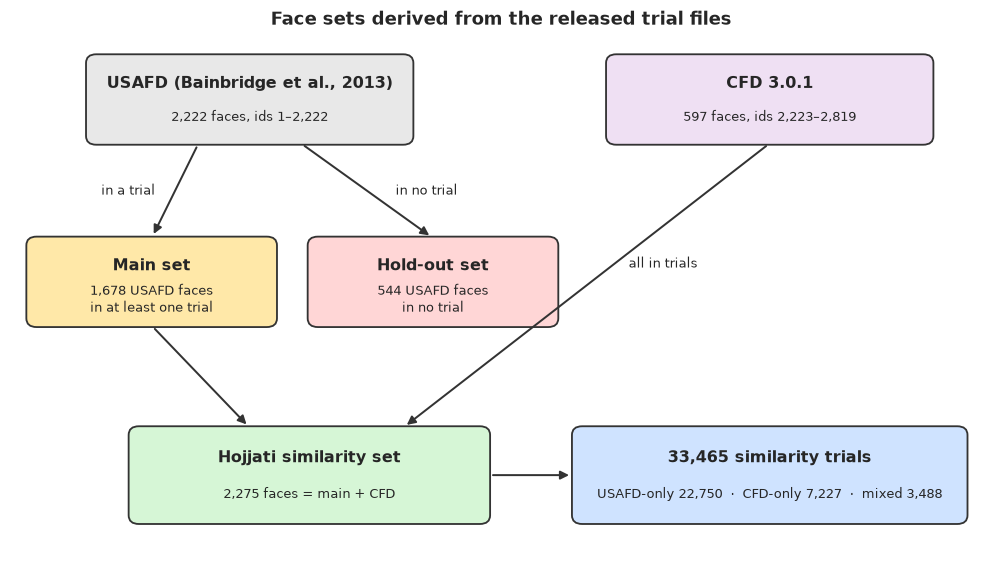

In [7]:
# ---- face-set flow figure (all counts taken from the variables above) ----
fig, ax = plt.subplots(figsize=(11.5, 6.2))
ax.set_xlim(0, 11.5); ax.set_ylim(0, 7.2); ax.axis("off")

def node(x, y, w, h, title, sub, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=color, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h * 0.68, title, ha="center", va="center", fontsize=10.5, fontweight="bold")
    ax.text(x + w / 2, y + h * 0.30, sub, ha="center", va="center", fontsize=8.8)

def link(x1, y1, x2, y2, label=None, dx=0.0, dy=0.0):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=1.3, color="#333333", shrinkA=3, shrinkB=3))
    if label:
        ax.text((x1 + x2) / 2 + dx, (y1 + y2) / 2 + dy, label, fontsize=8.5, ha="center", va="center",
                bbox=dict(fc="white", ec="none", pad=1.0))

node(0.9, 5.7, 3.8, 1.2, "USAFD (Bainbridge et al., 2013)", f"{N_USAFD:,} faces, ids 1–{N_USAFD:,}", "#e8e8e8")
node(7.0, 5.7, 3.8, 1.2, "CFD 3.0.1", f"{N_CFD:,} faces, ids {N_USAFD + 1:,}–{N_TOTAL:,}", "#efe0f3")
node(0.2, 3.2, 2.9, 1.2, "Main set", f"{len(main):,} USAFD faces\nin at least one trial", "#ffe8a8")
node(3.5, 3.2, 2.9, 1.2, "Hold-out set", f"{len(hold):,} USAFD faces\nin no trial", "#ffd6d6")
node(1.4, 0.5, 4.2, 1.3, "Hojjati similarity set", f"{len(main) + len(cfd):,} faces = main + CFD", "#d6f6d6")
node(6.6, 0.5, 4.6, 1.3, f"{len(trials):,} similarity trials",
     f"USAFD-only {tt.get('usafd_only', 0):,}  ·  CFD-only {tt.get('cfd_only', 0):,}  ·  mixed {tt.get('mixed', 0):,}",
     "#cfe3ff")
link(2.2, 5.7, 1.65, 4.4, "in a trial", dx=-0.55)
link(3.4, 5.7, 4.95, 4.4, "in no trial", dx=0.7)
link(1.65, 3.2, 2.8, 1.8)
link(8.9, 5.7, 4.6, 1.8, "all in trials", dx=0.9, dy=0.3)
link(5.6, 1.15, 6.6, 1.15)
ax.set_title("Face sets derived from the released trial files", fontsize=12)
save(fig, "03_face_set_flow")
plt.show()


## 4. Human alignment: reproduction of `Models_alignment.pkl`

**What alignment measures.** For each trial the model ranks the 4 candidates by their distance to the reference face (closest = most similar). That ranking is compared with the human ranking using Spearman's ρ. With 4 candidates, ρ can only take 11 values between −1 and +1 (steps of 0.2). A model's alignment is the **mean ρ over all trials**: 0 means the model ranks candidates no better than chance, 1 means it always agrees with people.

**Recipe** (identical to Hojjati's `utils.calculate_similarity_alignment`):

1. L2-normalise each embedding row.
2. Euclidean distance between the reference and each candidate.
3. Per trial: Spearman ρ between the model's ordering and the human ordering.
4. Mean over trials where ρ is defined.

The 14 face-recognition models and 2 non-recognition baselines (AAM, a shape-and-appearance model; StyleGAN2, a generative model) are computed on all trials, USAFD-only trials and CFD-only trials, and compared with the released values. The reproduction passes if every difference is below 10⁻⁶. AAM and StyleGAN2 are reproduced only because they are in the release: the thesis analyses the 14 recognition models alone (it concerns recognition models, and AAM was trained on the 544 hold-out faces). Per-trial values are kept in `per_trial` for Figure B.

In [8]:
# ============================================================ 4. Alignment reproduction
# Recipe = Hojjati utils.calculate_similarity_alignment (verbatim, quoted below):
#   E_D = squareform(pdist(embs, 'euclidean'))
#   for each trial: distances = [E_D[ref, cand_j] for j in 1..4]
#       model_order[ref] = trials[ref,0]; model_order[ref,1:] = argsort(distances)+1
#   Corr, _ = spearmanr(np.argsort(scores[idx,1:])+1, order[1:].tolist())
#   mean over non-NaN Corr
# i.e. L2-normalise rows, Euclidean distance, per-trial argsort of the four
# candidate distances (+1), per-trial argsort of the four human scores (+1),
# per-trial Spearman, mean over non-NaN trials.
MODELS = {
    "ArcFace18": "ARCFace18_glint360k_embs", "ArcFace34": "ARCFace34_glint360k_embs",
    "ArcFace50": "ARCFace50_glint360k_embs", "ArcFace100": "ARCFace100_glint360k_embs",
    "swinface": "swinface_embs", "FaceNet": "Facenet_embs", "FaceNet512": "Facenet512_embs",
    "Dlib": "Dlib_embs", "VGG-Face": "VGG-Face_embs", "GhostFaceNet": "GhostFaceNet_embs",
    "SFace": "SFace_embs", "DeepFace": "DeepFace_embs", "OpenFace": "OpenFace_embs",
    "DeepID": "DeepID_embs",
}
NON_RECOG = {"AAM": "AAM_embs", "StyleGAN2": "StyleGAN2_embs"}

def l2norm_rows(x):
    n = np.sqrt(np.sum(np.square(x), axis=1, keepdims=True))
    return x / n

def alignment(embs, trials, scores):
    e = l2norm_rows(embs)
    ed = squareform(pdist(e, "euclidean"))
    d = ed[trials[:, :1], trials[:, 1:]]
    model_order = np.argsort(d, axis=1) + 1           # 1-based ranks of candidates
    human = np.argsort(scores[:, 1:], axis=1) + 1     # 1-based human ranks
    rs = np.full(len(trials), np.nan)
    for i in range(len(trials)):
        r, _ = spearmanr(human[i], model_order[i])
        rs[i] = r
    ok = ~np.isnan(rs)
    return rs, ok

# masks: all-USAFD / all-CFD / mixed
def split_masks(trials):
    usafd = trials < N_USAFD
    return {"all": np.ones(len(trials), bool),
            "usafd": np.all(usafd, axis=1),
            "cfd": np.all(~usafd, axis=1),
            "mixed": ~(np.all(usafd, axis=1) | np.all(~usafd, axis=1))}

masks = split_masks(trials)
released = pickle.load(open(_walk(ZEN, "Models_alignment.pkl"), "rb"))
# released values are [CFD, USAFD, All]

rows = []
per_trial = {}   # model -> (per-trial rho, defined mask), reused in Figure B
for name, stem in list(MODELS.items()) + list(NON_RECOG.items()):
    emb = np.load(_walk(ZEN, "Similarity_task_images_embeds", f"{stem}.npy"))
    rs, ok = alignment(emb, trials, scores)
    per_trial[name] = (rs, ok)
    r = {"model": name, "family": FAMILY[name], "zen_stem": stem}
    r["computed_all"] = float(np.mean(rs[ok]))
    r["computed_usafd"] = float(np.mean(rs[ok & masks["usafd"]]))
    r["computed_cfd"] = float(np.mean(rs[ok & masks["cfd"]]))
    r["n_trials"] = int(ok.sum())
    r["n_nan"] = int((~ok).sum())
    if stem in released:
        cfd_v, usafd_v, all_v = released[stem]
        r["released_cfd"] = float(cfd_v)
        r["released_usafd"] = float(usafd_v)
        r["released_all"] = float(all_v)
        r["maxdiff"] = max(abs(r["computed_all"] - r["released_all"]),
                           abs(r["computed_usafd"] - r["released_usafd"]),
                           abs(r["computed_cfd"] - r["released_cfd"]))
    rows.append(r)
    print(f"{name:14s} computed all={r['computed_all']:.6f} usafd={r['computed_usafd']:.6f} "
          f"cfd={r['computed_cfd']:.6f} | maxdiff={r.get('maxdiff', float('nan')):.2e}")

al = pd.DataFrame(rows)
al.to_csv(os.path.join(OUT, "alignment.csv"), index=False)
maxdiff = al["maxdiff"].max() if "maxdiff" in al.columns else float("nan")
print(f"\nmax |computed - Models_alignment| over all models = {maxdiff:.3e} "
      f"-> reproduced {'exactly' if maxdiff < 1e-6 else 'NOT exactly'} "
      f"(tolerance 1e-6)")

ArcFace18      computed all=0.198661 usafd=0.178198 cfd=0.232738 | maxdiff=2.78e-17
ArcFace34      computed all=0.172108 usafd=0.157336 cfd=0.195766 | maxdiff=2.78e-17
ArcFace50      computed all=0.159223 usafd=0.141943 cfd=0.187768 | maxdiff=0.00e+00
ArcFace100     computed all=0.144724 usafd=0.129864 cfd=0.171247 | maxdiff=2.78e-17
swinface       computed all=0.152267 usafd=0.138980 cfd=0.175868 | maxdiff=2.78e-17
FaceNet        computed all=0.263678 usafd=0.247798 cfd=0.288252 | maxdiff=5.55e-17
FaceNet512     computed all=0.263487 usafd=0.247877 cfd=0.285374 | maxdiff=0.00e+00
Dlib           computed all=0.320843 usafd=0.297108 cfd=0.368701 | maxdiff=5.55e-17
VGG-Face       computed all=0.260415 usafd=0.238400 cfd=0.291518 | maxdiff=0.00e+00
GhostFaceNet   computed all=0.206652 usafd=0.190163 cfd=0.229085 | maxdiff=0.00e+00
SFace          computed all=0.195787 usafd=0.176088 cfd=0.218237 | maxdiff=0.00e+00
DeepFace       computed all=0.201130 usafd=0.167771 cfd=0.265947 | maxdiff=2

**Reading the output**

- Every model is reproduced exactly (largest difference 5.6 × 10⁻¹⁷, i.e. floating-point rounding).
- Alignment is low in absolute terms: **0.145 (ArcFace100) to 0.321 (Dlib)**.
- Within the ArcFace family, alignment **falls** as network depth rises: 0.199 → 0.172 → 0.159 → 0.145 for 18 → 34 → 50 → 100 layers.
- Every model aligns better on CFD-only trials than on USAFD-only trials. CFD photos are standardised (neutral expression, fixed pose and lighting), so less irrelevant image variation reaches the model.
- The two non-recognition baselines (AAM 0.196, StyleGAN2 0.202) sit in the middle of the recognition models. They are not part of the thesis analysis.

## 5. Recognition accuracy

**Task.** Each model judges whether two CFD photos show the same person. There are 1,494 *genuine* pairs (same identity) and 13,500 *impostor* pairs (different identities) from 566 identities. A pair's score is the cosine similarity of the two embeddings.

**Metrics**

| Metric | Meaning | Note |
|---|---|---|
| AUC | probability that a random genuine pair scores higher than a random impostor pair | reaches its ceiling (1.0) for the strongest models |
| d′ | distance between the genuine and impostor score distributions, in pooled-SD units (computed as Cohen's d) | keeps separating models after AUC saturates; **used as the main accuracy measure** |
| EER | error rate at the threshold where false accepts = false rejects | lower is better |
| TPR @ FPR = 10⁻³ / 10⁻⁴ | share of genuine pairs accepted when only 0.1% / 0.01% of impostors are accepted | the operating range of real face-recognition systems |

**Uncertainty.** 95% CIs come from 2,000 bootstrap resamples of *identities* (seed 1), because pairs that share a person are not independent. Each impostor pair is assigned to the identity of its first photo only, so these CIs are somewhat too narrow.

**Caution on TPR @ 10⁻⁴.** With 13,500 impostor pairs, the 10⁻⁴ threshold is set by the single highest impostor score, so this metric is unstable.

The cell also adds a `model_key` column so that `accuracy.csv` can be joined to `alignment.csv`.

In [9]:
# ============================================================ 5. Recognition accuracy
# Positive pairs: same identity; negative pairs: different identity (CFD).
# Expected: 1,494 positive, 13,500 negative; 566 identities, 158 with positives.
# For each released recognition model: load recognition pkl {path: emb(512,)},
# cosine similarity per pair; report AUC, d' (Cohen's d), EER, TPR@FPR 1e-3/1e-4,
# with 95% bootstrap CI resampling identities (2,000 resamples, seed 1).
def identity_of(path):
    parts = [x for x in str(path).split("/") if x]
    folder = parts[-2] if len(parts) > 1 else "?"
    for x in reversed(parts):
        if x.startswith("CFD-"):
            bits = x.split("-")
            return "-".join(bits[1:3]) if len(bits) >= 3 else folder
    return folder

pos = np.load(_walk(ZEN, "Recognition_task_pairs", "positive_pairs.npy"),
              allow_pickle=True)
neg = np.load(_walk(ZEN, "Recognition_task_pairs", "negative_pairs.npy"),
              allow_pickle=True)
print(f"pairs: {len(pos)} positive, {len(neg)} negative (expected 1494 / 13500)")
assert len(pos) == 1494 and len(neg) == 13500

pos_id = np.array([identity_of(p) for p in pos[:, 0]])
neg_id = np.array([identity_of(p) for p in neg[:, 0]])
all_id = np.r_[pos_id, neg_id]
uniq_ids = np.unique(all_id)
uniq_pos = np.unique(pos_id)
print(f"distinct identities: {len(uniq_ids)} (expected 566); "
      f"identities with positive pairs: {len(uniq_pos)} (expected 158)")

# mask: is each endpoint positive?
all_scores_pos = np.array([])
all_scores_neg = np.array([])
# pooled bootstrap: resample identities, take all scores belonging to them
def cos(a, b):
    va, vb = np.asarray(a), np.asarray(b)
    return float(va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb)))

def auc_score(pos_s, neg_s):
    x = np.r_[pos_s, neg_s]; y = np.r_[np.ones(len(pos_s)), np.zeros(len(neg_s))]
    return float(roc_auc_score(y, x))

def eer(pos_s, neg_s):
    fpr, tpr, _ = roc_curve(np.r_[np.ones(len(pos_s)), np.zeros(len(neg_s))],
                            np.r_[pos_s, neg_s], pos_label=1)
    i = int(np.argmin(np.abs(tpr - (1 - fpr))))
    return float((fpr[i] + (1 - tpr[i])) / 2)

def tpr_at_fpr(pos_s, neg_s, tf):
    k = int(np.floor(tf * len(neg_s)))
    if k < 1:
        return float(np.mean(pos_s > neg_s.max()))
    thr = np.sort(neg_s)[::-1][k - 1]
    return float(np.mean(pos_s >= thr))

def cohen_d(pos_s, neg_s):
    sp = np.sqrt((np.var(pos_s, ddof=1) + np.var(neg_s, ddof=1)) / 2.0)
    return float((pos_s.mean() - neg_s.mean()) / sp) if sp > 0 else np.nan

# recognition-pickle name -> alignment model name (join key between accuracy.csv and alignment.csv)
ACC_KEY = {"Arcface18_glint360k_": "ArcFace18", "Arcface34_glint360k_": "ArcFace34",
           "Arcface50_glint360k_": "ArcFace50", "Arcface100_glint360k_": "ArcFace100",
           "swinface_": "swinface", "Facenet_": "FaceNet", "Facenet512_": "FaceNet512", "Dlib_": "Dlib",
           "VGG-Face_": "VGG-Face", "GhostFaceNet_": "GhostFaceNet", "SFace_": "SFace",
           "DeepFace_": "DeepFace", "OpenFace_": "OpenFace", "DeepID_": "DeepID"}
pair_scores = {}   # model -> (genuine scores, impostor scores), reused in Figure C

acc_rows = []
for f in sorted(os.listdir(_walk(ZEN, "Recognition_task_images_embeds"))):
    if not f.endswith("_embs.pkl"):
        continue
    model = f[:-8]
    with open(_walk(ZEN, "Recognition_task_images_embeds", f), "rb") as fh:
        d = pickle.load(fh)
    p_s = np.array([cos(d[str(pos[i, 0])], d[str(pos[i, 1])]) for i in range(len(pos))])
    n_s = np.array([cos(d[str(neg[i, 0])], d[str(neg[i, 1])]) for i in range(len(neg))])
    pair_scores[model] = (p_s, n_s)
    all_s = np.r_[p_s, n_s]
    is_pos = np.r_[np.ones(len(p_s)), np.zeros(len(n_s))]
    groups = np.r_[pos_id, neg_id]
    idx_by_id = [np.flatnonzero(groups == g) for g in uniq_ids]
    rng_b = np.random.default_rng(SEED)
    n_boot = 2000
    boots = {k: np.full(n_boot, np.nan) for k in ("auc", "d", "eer", "tpr3", "tpr4")}
    for b in range(n_boot):
        pick = rng_b.integers(0, len(uniq_ids), len(uniq_ids))
        rb = np.concatenate([idx_by_id[q] for q in pick])
        ps = all_s[rb[is_pos[rb] == 1]]; ns = all_s[rb[is_pos[rb] == 0]]
        if len(ps) < 2 or len(ns) < 2:
            continue
        boots["auc"][b] = auc_score(ps, ns)
        boots["d"][b] = cohen_d(ps, ns)
        boots["eer"][b] = eer(ps, ns)
        boots["tpr3"][b] = tpr_at_fpr(ps, ns, 1e-3)
        boots["tpr4"][b] = tpr_at_fpr(ps, ns, 1e-4)
    def ci(key):
        v = boots[key][~np.isnan(boots[key])]
        return (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) if len(v) >= 10 else (np.nan, np.nan)
    auc_v = auc_score(p_s, n_s)
    acc_rows.append(dict(model=model, model_key=ACC_KEY.get(model, model), n_pos=len(pos), n_neg=len(neg),
                         n_ids=len(uniq_ids), n_ids_pos=len(uniq_pos),
                         auc=auc_v, auc_lo=ci("auc")[0], auc_hi=ci("auc")[1],
                         dprime=cohen_d(p_s, n_s), d_lo=ci("d")[0], d_hi=ci("d")[1],
                         eer=eer(p_s, n_s), eer_lo=ci("eer")[0], eer_hi=ci("eer")[1],
                         tpr_1e3=tpr_at_fpr(p_s, n_s, 1e-3),
                         tpr3_lo=ci("tpr3")[0], tpr3_hi=ci("tpr3")[1],
                         tpr_1e4=tpr_at_fpr(p_s, n_s, 1e-4),
                         tpr4_lo=ci("tpr4")[0], tpr4_hi=ci("tpr4")[1]))
acc = pd.DataFrame(acc_rows).sort_values("auc", ascending=False).reset_index(drop=True)
assert acc["model_key"].isin(list(MODELS)).all(), "unmapped model name in ACC_KEY"
acc.to_csv(os.path.join(OUT, "accuracy.csv"), index=False)
print(acc[["model", "auc", "auc_lo", "auc_hi", "dprime", "d_lo", "d_hi",
           "eer", "tpr_1e3", "tpr_1e4"]].round(4).to_string(index=False))
print(f"\nAUC range: {acc['auc'].min():.4f}..{acc['auc'].max():.4f}; "
      f"d' range: {acc['dprime'].min():.2f}..{acc['dprime'].max():.2f} "
      f"(expected ~0.78-9.57)")
tied = acc[acc["auc"].round(4) >= 1.0]   # AUC = 1.0000 at 4 decimals
print(f"tied at AUC = 1.0000: {sorted(tied['model'].tolist())}")
for metric in ("dprime", "eer", "tpr_1e3", "tpr_1e4"):
    v = tied[metric]
    print(f"  {metric} separates tied models: {v.nunique() > 1} "
          f"({v.nunique()} distinct values of {len(v)})")

pairs: 1494 positive, 13500 negative (expected 1494 / 13500)
distinct identities: 566 (expected 566); identities with positive pairs: 158 (expected 158)
                model    auc  auc_lo  auc_hi  dprime   d_lo   d_hi    eer  tpr_1e3  tpr_1e4
Arcface100_glint360k_ 1.0000  1.0000  1.0000  9.5741 9.2984 9.8518 0.0000   1.0000   1.0000
 Arcface50_glint360k_ 1.0000  1.0000  1.0000  8.6209 8.3756 8.8836 0.0001   1.0000   0.9987
 Arcface34_glint360k_ 1.0000  1.0000  1.0000  8.0514 7.7756 8.3425 0.0006   1.0000   0.9980
            swinface_ 1.0000  1.0000  1.0000  7.2028 6.8758 7.5486 0.0019   0.9980   0.9946
 Arcface18_glint360k_ 0.9999  0.9998  1.0000  6.2954 6.0576 6.5460 0.0027   0.9946   0.9806
             Facenet_ 0.9987  0.9981  0.9992  4.6207 4.4597 4.7947 0.0181   0.8126   0.6178
          Facenet512_ 0.9970  0.9958  0.9981  4.1907 4.0396 4.3548 0.0281   0.7744   0.5114
                Dlib_ 0.9964  0.9952  0.9973  3.2496 3.1590 3.3346 0.0277   0.6693   0.2858
            VGG-Fac

**Reading the output**

- AUC is at or near 1.0 for ArcFace18/34/50/100 and SwinFace, so **AUC cannot rank the strongest models**.
- d′ spans **0.78 (DeepID) to 9.57 (ArcFace100)** and keeps ordering the models where AUC cannot.
- AUC and d′ do not always agree on the order: Dlib has a higher AUC than VGG-Face (0.9964 vs 0.9952) but a lower d′ (3.25 vs 4.09). AUC depends only on rank order, while d′ also depends on how spread out the scores are.
- DeepFace, OpenFace and DeepID form a clearly weaker group (AUC 0.78–0.83).

### 5b. Model table for the *Models* page

One table for the 14 recognition models (AAM and StyleGAN2 are excluded from the thesis), written to `models_table.csv`:
- family;
- embedding size, read from the released arrays and checked against the recognition files;
- alignment on USAFD-only trials (the H1 predictor) and on all trials;
- d′ with its 95% CI.

The cell also measures how much of the differences in alignment d′ explains. H1 controls for d′ and d′², so the share of alignment they explain (R²) is the part the test cannot use. *Validation and power* builds on this number.

In [10]:
# ---- 5b. Model table (14 recognition models) ----
rec_dir = _walk(ZEN, "Recognition_task_images_embeds")
rec_file = {ACC_KEY[f[:-8]]: f for f in os.listdir(rec_dir) if f.endswith("_embs.pkl")}
size_rows = []
for name, stem in MODELS.items():                       # MODELS = the 14 recognition models
    sim_dim = int(np.load(_walk(ZEN, "Similarity_task_images_embeds", f"{stem}.npy"), mmap_mode="r").shape[1])
    with open(os.path.join(rec_dir, rec_file[name]), "rb") as fh:
        rec_dim = int(np.asarray(next(iter(pickle.load(fh).values()))).ravel().shape[0])
    size_rows.append(dict(model=name, family=FAMILY[name], emb_dim=sim_dim, rec_dim=rec_dim))
sizes = pd.DataFrame(size_rows)

mt = (sizes
      .merge(al[["model", "computed_usafd", "computed_all"]], on="model")
      .merge(acc[["model_key", "dprime", "d_lo", "d_hi"]], left_on="model", right_on="model_key")
      .drop(columns="model_key")
      .rename(columns={"computed_usafd": "align_usafd", "computed_all": "align_all"})
      .sort_values("align_usafd", ascending=False).reset_index(drop=True))
assert len(mt) == 14, len(mt)
mismatch = mt[mt.emb_dim != mt.rec_dim]
print("embedding size: similarity vs recognition files agree for all 14 models"
      if mismatch.empty else f"SIZE MISMATCH:\n{mismatch[['model', 'emb_dim', 'rec_dim']]}")

# share of alignment explained by d' and d'^2 (the controls in H1)
zs_ = lambda v: (v - v.mean()) / v.std()
x = zs_(mt.align_usafd.to_numpy())
dc = mt.dprime.to_numpy() - mt.dprime.mean()
Xc = np.column_stack([np.ones(len(mt)), zs_(dc), zs_(dc ** 2)])
resid = x - Xc @ np.linalg.lstsq(Xc, x, rcond=None)[0]
r2_align_dprime = 1 - resid.var() / x.var()
rho_ad, p_ad = spearmanr(mt.align_usafd, mt.dprime)
print(f"families: {mt.family.nunique()}")
print(f"alignment (USAFD) explained by d' and d'^2: R^2 = {r2_align_dprime:.3f} "
      f"-> {100 * (1 - r2_align_dprime):.0f}% of alignment is left for the H1 test")
print(f"Spearman rho(alignment, d') = {rho_ad:.2f} (p = {p_ad:.2g}; descriptive)")

mt.to_csv(os.path.join(OUT, "models_table.csv"), index=False)
print("\nwrote results/data/models_table.csv")
print(mt.round({"align_usafd": 3, "align_all": 3, "dprime": 2, "d_lo": 2, "d_hi": 2}).to_string(index=False))


embedding size: similarity vs recognition files agree for all 14 models
families: 10
alignment (USAFD) explained by d' and d'^2: R^2 = 0.546 -> 45% of alignment is left for the H1 test
Spearman rho(alignment, d') = -0.25 (p = 0.38; descriptive)

wrote results/data/models_table.csv
       model       family  emb_dim  rec_dim  align_usafd  align_all  dprime  d_lo  d_hi
        Dlib         Dlib      128      128        0.297      0.321    3.25  3.16  3.33
  FaceNet512      FaceNet      512      512        0.248      0.263    4.19  4.04  4.35
     FaceNet      FaceNet      128      128        0.248      0.264    4.62  4.46  4.79
    VGG-Face     VGG-Face     4096     4096        0.238      0.260    4.09  3.90  4.30
GhostFaceNet GhostFaceNet      512      512        0.190      0.207    3.39  3.19  3.62
    OpenFace     OpenFace      128      128        0.179      0.212    1.11  1.02  1.19
   ArcFace18      ArcFace      512      512        0.178      0.199    6.30  6.06  6.55
       SFace  

## 6. Fold contamination in the released cross-validation splits

The release includes the splits used to train Hojjati's trait predictors: 5 outer folds (a test set each), and within each outer fold 10 inner train/validation splits. The splits are made at the level of **trials**, so one face can appear in a test trial and in a training trial of the same outer fold. In that case the face is no longer unseen at test time.

This cell counts, for each outer fold, how many distinct test faces also appear in any training or validation block of that fold. It first prints a check of the array columns. Each split array has 3 columns, and the check shows that all three hold face ids (0–2,818). Each row is therefore a set of three faces, and all three columns are used.

In [11]:
# ============================================================ 6. Fold contamination
# The release's cross-fold splits live in Cross_folds_splits/: per (outer fold f
# in 1..5, inner fold v in 1..10) a train and a val array, each (n, 3) int16 of
# 0-based face ids (trials: reference, candidate, ?).  Contamination = share of
# test faces (f<f>_test.npy) that also appear in any train or val block of the
# same outer fold.
CFD_COUNTS = _walk(ZEN, "Cross_folds_splits")
_ex = np.load(_walk(CFD_COUNTS, "f1_f1_train.npy"))
if _ex.ndim == 2:
    print("column check (f1_f1_train.npy): column -> min, max, distinct values")
    for j in range(_ex.shape[1]):
        print(f"  col {j}: {int(_ex[:, j].min())}..{int(_ex[:, j].max())}, {len(np.unique(_ex[:, j])):,} distinct")
    print("  a column outside 0..2818, or with very few distinct values, is not a face id\n")
leak_rows = []
test_all, trainval_all = set(), set()
for t in range(1, 6):
    test = set(int(x) for x in np.rint(np.load(_walk(CFD_COUNTS, f"f{t}_test.npy"))).ravel())
    train, val = set(), set()
    for v in range(1, 11):
        train |= set(int(x) for x in np.rint(np.load(_walk(CFD_COUNTS, f"f{t}_f{v}_train.npy"))).ravel())
        val |= set(int(x) for x in np.rint(np.load(_walk(CFD_COUNTS, f"f{t}_f{v}_val.npy"))).ravel())
    trainval = train | val
    test_all |= test; trainval_all |= trainval
    leak_rows.append(dict(test_fold=t, test_faces=len(test),
                          train_faces_union10=len(train), val_faces_union10=len(val),
                          test_in_train_u10=len(test & train),
                          test_in_val_u10=len(test & val),
                          test_in_trainval_u10=len(test & trainval),
                          pct_u10=round(100 * len(test & trainval) / len(test), 2)))
leak = pd.DataFrame(leak_rows)
leak.to_csv(os.path.join(OUT, "fold_contamination.csv"), index=False)
print(leak.to_string(index=False))
print("\nOnly the within-fold numbers are a contamination measure. Pooled over folds, every "
      "test face is a training face in some other fold, as in any cross-validation.")


column check (f1_f1_train.npy): column -> min, max, distinct values
  col 0: 0..2818, 1,638 distinct
  col 1: 0..2818, 1,638 distinct
  col 2: 0..2818, 1,638 distinct
  a column outside 0..2818, or with very few distinct values, is not a face id

 test_fold  test_faces  train_faces_union10  val_faces_union10  test_in_train_u10  test_in_val_u10  test_in_trainval_u10  pct_u10
         1         591                 1820               1820                203              203                   203    34.35
         2         575                 1820               1820                198              198                   198    34.43
         3         590                 1820               1820                209              209                   209    35.42
         4         573                 1820               1820                192              192                   192    33.51
         5         565                 1820               1820                200              200     

**Reading the output**

- In every outer fold, **33.5–35.4% of test faces also appear in training or validation trials of that same fold**. Hojjati's cross-validated scores are therefore not fully out-of-sample at the face level.
- The training-union and validation-union counts are identical (1,820 faces) because, across the 10 inner splits, every non-test face is used for both training and validation.
- The column check confirms that all three columns are face ids, so these counts use every face in a row.
- Pooling the five folds is not a contamination measure: in any cross-validation, every test face is a training face in some other fold.

## 7. Trait ratings and composite scores

**Data.** The `All Data` sheet of `psychology-attributes.xlsx` contains one row per (face, survey) with two 26-column survey forms. Each face was rated by about 15 workers on 20 trait pairs on a 1–9 scale. Each pair has a positive item and its antonym, e.g. *trustworthy* / *untrustworthy*.

**Composite score per face and trait** = (mean of the positive item + (10 − mean of the antonym)) / 2. Reversing the antonym puts both items on the same direction, and averaging them reduces response bias. The result is written to `trait_scores_20.csv` (2,222 faces × 20 traits).

The 14 traits used in the thesis (`TRAITS_14`) are the social and personality traits. The other 6 (typical, memorable, emotional, familiar, common, friendly) are kept for reliability reporting.

**Two checks:**

- **Rater 1236** contributes 1,464 ratings, far more than any other worker. Section 8 repeats the reliability analysis without this rater.
- The composites are compared with the same composite built from Bainbridge's `Final Values` sheet. The 95th-percentile difference is 0.08 but the maximum is 0.47, so a few faces differ noticeably. The reason (probably rater exclusions in `Final Values`) is not documented. The thesis uses the composites rebuilt from the raw ratings.

In [12]:
# ============================================================ 7. Ratings and trait scores
# "All Data" sheet of psychology-attributes.xlsx: two 26-column survey blocks
# (cols 2..27 with id=subID, cols 28..53 with id=subID.1).  Per face and
# attribute: score = mean of all non-missing ratings, with antonym reversed
# (10 - x); primary = mean over both forms.
psy = pd.read_excel(_walk(RAW, "2kattributes", "psychology attributes",
                          "psychology-attributes.xlsx"), sheet_name="All Data")
per_face = psy.groupby("Image #").size()
print(f"psychology rows={len(psy)} faces={psy['Image #'].nunique()}; "
      f"rows/face: {per_face.value_counts().sort_index().to_dict()}")
# rater 1236: count per-form occurrences (a row where the worker did both
# surveys counts once per form) -> 741 (form 1) + 723 (form 2) = 1,464
n_1236_f1 = int((psy["subID"] == 1236).sum())
n_1236_f2 = int((psy["subID.1"] == 1236).sum())
n_1236 = n_1236_f1 + n_1236_f2
print(f"rater id 1236 rows: {n_1236} (form1 {n_1236_f1} + form2 {n_1236_f2}; expected ~1,464)")

TRAIT_PAIRS = [
    ("typical", "atypical"), ("memorable", "forgettable"), ("emotStable", "emotUnstable"),
    ("attractive", "unattractive"), ("emotional", "unemotional"), ("familiar", "unfamiliar"),
    ("friendly", "unfriendly"), ("happy", "unhappy"), ("responsible", "irresponsible"),
    ("intelligent", "unintelligent"), ("trustworthy", "untrustworthy"), ("common", "uncommon"),
    ("confident", "uncertain"), ("caring", "cold"), ("calm", "aggressive"),
    ("humble", "egotistic"), ("interesting", "boring"), ("normal", "weird"),
    ("kind", "mean"), ("sociable", "introverted"),
]
TRAITS_14 = ["attractive", "emotStable", "normal", "responsible", "trustworthy",
             "confident", "sociable", "caring", "humble", "calm", "happy",
             "kind", "intelligent", "interesting"]

labels = sorted(psy["Image #"].unique())
pool = pd.DataFrame({"label": labels})
for pname, aname in TRAIT_PAIRS:
    m_pos = psy.groupby("Image #")[pname].mean()
    m_ant = psy.groupby("Image #")[aname].mean()
    pool[pname] = (m_pos.reindex(pool["label"]).values
                   + (10 - m_ant.reindex(pool["label"]).values)) / 2
pool.to_csv(os.path.join(OUT, "trait_scores_20.csv"), index=False)
print(f"\nwrote results/data/trait_scores_20.csv ({len(pool)} faces x {len(TRAIT_PAIRS)} traits)")

# per-face number of ratings (min/median/max)
def n_ratings(col):
    return psy.groupby("Image #")[col].apply(lambda s: int(s.notna().sum()))
n_pos = n_ratings(TRAITS_14[0])
print(f"ratings per face (e.g. attractive): min {n_pos.min()}, median {int(n_pos.median())}, "
      f"max {n_pos.max()}")

# difference from "Final Values" (do NOT use Final Values as the target)
# Final Values holds per-face means of the raw survey items; rebuild the same
# composite from it and compare.
_fv = pd.read_excel(_walk(RAW, "2kattributes", "psychology attributes",
                          "psychology-attributes.xlsx"), sheet_name="Final Values")
_fv = _fv.set_index("Image #")
fv_pool = pd.DataFrame({"label": labels})
for pname, aname in TRAIT_PAIRS:
    fv_pool[pname] = (_fv[pname].reindex(fv_pool["label"]).values
                    + (10 - _fv[aname].reindex(fv_pool["label"]).values)) / 2
diff = np.abs(pool.set_index("label") - fv_pool.set_index("label"))
print(f"max |pooled - Final Values composite| = {diff.max().max():.6f}; "
      f"95th percentile = {np.nanpercentile(diff.values, 95):.6f}")

psychology rows=33430 faces=2222; rows/face: {15: 2122, 16: 100}
rater id 1236 rows: 1464 (form1 741 + form2 723; expected ~1,464)

wrote results/data/trait_scores_20.csv (2222 faces x 20 traits)
ratings per face (e.g. attractive): min 14, median 15, max 16
max |pooled - Final Values composite| = 0.474359; 95th percentile = 0.082051


## 8. Reliability of the human trait scores

**Why it matters.** A face's trait score is an average over about 15 raters, so it contains measurement noise. Reliability says how much of the variation across faces is stable signal. It also sets a ceiling: no model can correlate with a trait score more strongly than √reliability.

**Method (split-half with Spearman–Brown correction):**

1. Randomly split the raters into two halves (by worker id, across both survey forms).
2. Build the composite score of every face from each half separately.
3. Correlate the two halves across faces (Spearman).
4. Correct to full panel size: r_SB = 2r / (1 + r).
5. Repeat 200 times and average.

This is done with all raters and again without rater 1236.

In [13]:
# ============================================================ 8. Reliability
# 200 random split-halves of the raters within each form; correlation across
# faces of the two half-means; Spearman-Brown correction.  Canonical value =
# mean over splits, all raters.  Reported for all 2,222 faces.
SEED = 1
N_SPLITS = 200
ANTONYM = {"attractive": "unattractive", "emotStable": "emotUnstable",
            "normal": "weird", "responsible": "irresponsible",
            "trustworthy": "untrustworthy", "confident": "uncertain",
            "sociable": "introverted", "caring": "cold", "humble": "egotistic",
            "calm": "aggressive", "happy": "unhappy", "kind": "mean",
            "intelligent": "unintelligent", "interesting": "boring",
            "typical": "atypical", "memorable": "forgettable",
            "emotional": "unemotional", "familiar": "unfamiliar",
            "common": "uncommon", "friendly": "unfriendly"}

cols = list(psy.columns)
block_of = {}
for a, b, idc in [(2, 28, "subID"), (28, 54, "subID.1")]:
    for c in cols[a:b]:
        block_of[c] = idc
lab_idx = {lab: i for i, lab in enumerate(labels)}
n_faces = len(labels)

def rows_for(col, frame):
    sub = frame[["Image #", block_of[col], col]].copy()
    sub["v"] = pd.to_numeric(sub[col], errors="coerce")
    sub = sub.dropna(subset=["v"])
    return (sub["Image #"].map(lab_idx).values.astype(np.int64),
            sub["v"].values.astype(float),
            sub[block_of[col]].values.astype(np.int64))

def half_means(fidx, vals, half):
    out = []
    for h in (0, 1):
        sel = half == h
        n = np.bincount(fidx[sel], minlength=n_faces).astype(float)
        s = np.bincount(fidx[sel], weights=vals[sel], minlength=n_faces)
        out.append(np.where(n > 0, s / np.maximum(n, 1), np.nan))
    return out[0], out[1]

def spearman(a, b):
    ra = pd.Series(a).rank().to_numpy()
    rb = pd.Series(b).rank().to_numpy()
    return float(np.corrcoef(ra, rb)[0, 1])

def sb(r):
    return 2 * r / (1 + r)

rng = np.random.default_rng(SEED)
rel_rows = []
for pname, aname in TRAIT_PAIRS:
    fp, vp, ip = rows_for(pname, psy)
    fa, va, ia = rows_for(aname, psy)
    ids_all = np.unique(np.concatenate([ip, ia]))
    rs = []
    for _ in range(N_SPLITS):
        id_half = dict(zip(ids_all, rng.integers(0, 2, size=len(ids_all))))
        hp = np.array([id_half[int(v)] for v in ip])
        ha = np.array([id_half[int(v)] for v in ia])
        p0, p1 = half_means(fp, vp, hp)
        a0, a1 = half_means(fa, va, ha)
        s0, s1 = (p0 + (10 - a0)) / 2, (p1 + (10 - a1)) / 2
        ok = ~np.isnan(s0) & ~np.isnan(s1)
        if ok.sum() > 10:
            rs.append(spearman(s0[ok], s1[ok]))
    r = float(np.mean(rs))
    rel_rows.append(dict(trait=pname, r_half=r, sb_spearman_brown=sb(r),
                         n_raters=int(len(ids_all))))
rel = pd.DataFrame(rel_rows)
rel_14 = rel[rel["trait"].isin(TRAITS_14)]
print("14-trait SB: mean %.3f, range %.3f..%.3f" % (
    rel_14["sb_spearman_brown"].mean(),
    rel_14["sb_spearman_brown"].min(), rel_14["sb_spearman_brown"].max()))
print("20-trait SB: mean %.3f, range %.3f..%.3f (familiar %.3f, happy %.3f)" % (
    rel["sb_spearman_brown"].mean(),
    rel["sb_spearman_brown"].min(), rel["sb_spearman_brown"].max(),
    rel.loc[rel["trait"] == "familiar", "sb_spearman_brown"].iloc[0],
    rel.loc[rel["trait"] == "happy", "sb_spearman_brown"].iloc[0]))

# without rater 1236
drop = ~((psy["subID"] == 1236) | (psy["subID.1"] == 1236))
rel_rows2 = []
for pname, aname in TRAIT_PAIRS:
    fp, vp, ip = rows_for(pname, psy[drop])
    fa, va, ia = rows_for(aname, psy[drop])
    ids_all = np.unique(np.concatenate([ip, ia]))
    rs = []
    for _ in range(N_SPLITS):
        id_half = dict(zip(ids_all, rng.integers(0, 2, size=len(ids_all))))
        hp = np.array([id_half[int(v)] for v in ip])
        ha = np.array([id_half[int(v)] for v in ia])
        p0, p1 = half_means(fp, vp, hp)
        a0, a1 = half_means(fa, va, ha)
        s0, s1 = (p0 + (10 - a0)) / 2, (p1 + (10 - a1)) / 2
        ok = ~np.isnan(s0) & ~np.isnan(s1)
        if ok.sum() > 10:
            rs.append(spearman(s0[ok], s1[ok]))
    r = float(np.mean(rs))
    rel_rows2.append(dict(trait=pname, sb_no1236=sb(r)))
rel_no1236 = pd.DataFrame(rel_rows2)
rel_all = rel.merge(rel_no1236, on="trait")
rel_all.to_csv(os.path.join(OUT, "reliability.csv"), index=False)
print("\nper-trait (all raters vs without rater 1236):")
print(rel_all.round(3).to_string(index=False))

14-trait SB: mean 0.783, range 0.678..0.890
20-trait SB: mean 0.736, range 0.464..0.890 (familiar 0.464, happy 0.890)

per-trait (all raters vs without rater 1236):
      trait  r_half  sb_spearman_brown  n_raters  sb_no1236
    typical   0.376              0.547      1273      0.514
  memorable   0.427              0.598      1274      0.589
 emotStable   0.561              0.719      1274      0.706
 attractive   0.792              0.884      1274      0.877
  emotional   0.606              0.755      1274      0.737
   familiar   0.302              0.464      1273      0.453
   friendly   0.772              0.872      1273      0.865
      happy   0.802              0.890      1274      0.883
responsible   0.595              0.746      1274      0.739
intelligent   0.513              0.678      1271      0.676
trustworthy   0.662              0.796      1274      0.792
     common   0.358              0.528      1274      0.503
  confident   0.591              0.743      1271      0

**Reading the output**

- The 14 core traits are reliable: **mean 0.78** (lowest *intelligent* 0.68, highest *happy* 0.89).
- The traits outside the core set are much weaker: *familiar* 0.46, *common* 0.53, *typical* 0.55, *memorable* 0.60. Predictions of these traits will look poor however good the model is.
- Removing rater 1236 **lowers** reliability slightly for every trait (by at most 0.03), so this rater adds signal rather than noise.
- Values are computed on all 2,222 faces.

## 9. Structure of the 14 social traits

**Question.** Are the 14 traits 14 separate judgements, or a few underlying dimensions? This matters for interpreting any per-trait result: if the traits are highly correlated, a model that predicts one will predict most of them.

**Computed separately for the main set and the hold-out set:**

- correlation matrix, mean |r| and the number of pairs (of 91) with |r| > 0.5;
- share of variance on the first principal component (PC1);
- **parallel analysis**: each trait is shuffled independently 1,000 times to break all correlations. A component is kept if its eigenvalue beats the shuffled data. Both the usual mean criterion and the stricter 95th-percentile criterion are reported.

Eigenvalues and null thresholds are kept in `scree` for Figure G.

In [14]:
# ============================================================ 9. Trait structure (14 traits)
# On main and hold-out separately: correlation matrix (heatmap), mean |r|,
# pairs with |r| > 0.5, PC1 variance share, parallel analysis (1,000 column-
# shuffled datasets; components counted against the null mean and the null
# 95th percentile).
fs = pd.read_csv(os.path.join(OUT, "face_sets.csv"))
main_ids = sorted(fs.loc[fs["set"] == "main", "id"].tolist())
hold_ids = sorted(fs.loc[fs["set"] == "holdout", "id"].tolist())

Y14 = pool.set_index("label")[TRAITS_14]
N_PERM = 1000
struct_rows = []
matrices = {}
scree = {}   # eigenvalues and null thresholds, reused in Figure G
for tag, labs in (("main", main_ids), ("holdout", hold_ids)):
    Y = Y14.loc[Y14.index.isin(labs)].reindex(labs)
    X = Y.to_numpy(float)
    R = np.corrcoef(X.T)
    matrices[tag] = R
    k = len(TRAITS_14)
    iu = np.triu_indices(k, 1)
    absr = np.abs(R[iu])
    ev = np.linalg.eigvalsh(R)[::-1]
    share1 = ev[0] / ev.sum()
    rng_p = np.random.default_rng(SEED)
    null_ev = np.empty((N_PERM, k))
    for p in range(N_PERM):
        Xp = np.column_stack([rng_p.permutation(X[:, j]) for j in range(k)])
        null_ev[p] = np.linalg.eigvalsh(np.corrcoef(Xp.T))[::-1]
    n_scree = int((ev > null_ev.mean(axis=0)).sum())
    null_p95 = np.percentile(null_ev, 95, axis=0)
    n_scree_p95 = int((ev > null_p95).sum())
    scree[tag] = dict(ev=ev, null_mean=null_ev.mean(axis=0), null_p95=null_p95)
    struct_rows.append(dict(set=tag, n=len(labs), mean_abs_r=float(absr.mean()),
                            max_abs_r=float(absr.max()),
                            n_gt_05=int((absr > 0.5).sum()),
                            eigen1=float(ev[0]), var_share_factor1=float(share1),
                            n_eigen_gt_1=int((ev > 1).sum()),
                            n_eigen_above_parallel=n_scree,
                            n_eigen_above_parallel_p95=n_scree_p95,
                            null_eigen1_mean=float(null_ev[:, 0].mean()),
                            null_eigen1_p95=float(np.percentile(null_ev[:, 0], 95))))
    print(f"{tag}: n={len(labs)} mean|r|={absr.mean():.3f} max|r|={absr.max():.3f} "
          f"pairs>0.5={(absr>0.5).sum()} factor1={share1*100:.1f}% "
          f"parallel(mean)={n_scree} parallel(p95)={n_scree_p95} null_eig1_mean={null_ev[:,0].mean():.3f}")

st = pd.DataFrame(struct_rows)
st.to_csv(os.path.join(OUT, "trait_structure.csv"), index=False)


main: n=1678 mean|r|=0.709 max|r|=0.949 pairs>0.5=83 factor1=73.8% parallel(mean)=2 parallel(p95)=2 null_eig1_mean=1.155
holdout: n=544 mean|r|=0.646 max|r|=0.948 pairs>0.5=72 factor1=68.2% parallel(mean)=2 parallel(p95)=2 null_eig1_mean=1.277


**Reading the output**

- The traits are **close to one-dimensional**. In the main set, mean |r| = 0.71, 83 of 91 pairs exceed |r| = 0.5, and PC1 explains 73.8% of the variance.
- Parallel analysis keeps 2 components in both sets.
- The hold-out set is a little less tightly correlated (mean |r| 0.65, PC1 68.2%). This fits section 11: the hold-out faces have a different age and race mix.
- Consequence for the thesis: correlations between traits are expected to be high whatever a model does. Claims about a model producing a "richer" trait structure need a baseline that accounts for this.

## 10. Memorability

Bainbridge's memorability experiment gives, for each face, a **hit rate** (share of participants who recognised the face on its repeat) and a **false-alarm rate** (share who wrongly claimed to have seen it before). d′ = z(hit rate) − z(false-alarm rate) combines both and corrects for the tendency to say "seen it".

Rates of exactly 0 or 1 give infinite z-scores. They are clipped at 10⁻⁶, which yields extreme d′ values, and the cell reports how many faces are affected (7 faces in the current run, too few to matter for averages). A log-linear correction would be better, but it needs the per-face trial counts, which the release does not include. Split-half reliability cannot be computed because only per-face aggregates are available.

In [15]:
# ============================================================ 10. Memorability
# Hit rate, false-alarm rate and d' per face; means and SDs. Paper: hit rate
# 51.6% SD 12.6, false alarms 14.4% SD 8.7.
mem = pd.read_excel(_walk(RAW, "2kmemorability", "memorability-scores.xlsx"))
mem["d_prime"] = stats.norm.ppf(mem["Hit Rate (HR)"].clip(1e-6, 1 - 1e-6)) \
    - stats.norm.ppf(mem["False Alarm Rate (FAR)"].clip(1e-6, 1 - 1e-6))
n_clip = int(((mem["Hit Rate (HR)"] <= 0) | (mem["Hit Rate (HR)"] >= 1) |
               (mem["False Alarm Rate (FAR)"] <= 0) | (mem["False Alarm Rate (FAR)"] >= 1)).sum())
print(f"memorability faces: {len(mem)}")
print(f"mean hit rate = {mem['Hit Rate (HR)'].mean()*100:.2f}% "
      f"(SD {mem['Hit Rate (HR)'].std(ddof=1)*100:.2f})")
print(f"mean FAR = {mem['False Alarm Rate (FAR)'].mean()*100:.2f}% "
      f"(SD {mem['False Alarm Rate (FAR)'].std(ddof=1)*100:.2f})")
print(f"mean d' = {mem['d_prime'].mean():.3f} (SD {mem['d_prime'].std(ddof=1):.3f})")
print(f"faces with a rate at 0 or 1 (d' clipped at 1e-6): {n_clip}")
print("Split-half reliability: not computable (memorability has no rater-level "
      "data; only aggregated hits/misses per face).")

memorability faces: 2222
mean hit rate = 51.61% (SD 12.62)
mean FAR = 14.41% (SD 8.65)
mean d' = 1.201 (SD 0.569)
faces with a rate at 0 or 1 (d' clipped at 1e-6): 7
Split-half reliability: not computable (memorability has no rater-level data; only aggregated hits/misses per face).


## 11. Demographics of the face sets

**Labels.** Race and gender come from the `Final Values` sheet of `demographic-others-labels.xlsx`, Bainbridge's per-face aggregate over 12 raters. Age is that sheet's mean age code rounded to five bins (<20, 20–30, 30–45, 45–60, 60+). These are **perceived** demographics, not self-reports.

**Output:**

- counts and percentages by set (written to `demographics_by_set.csv`);
- chi-square tests of whether the main and hold-out sets differ in composition (Middle Eastern, South Asian and Other are merged for the race test because their counts are too small; missing age is excluded);
- the race × gender table for the main set, which decides which subgroup comparisons are feasible.

In [16]:
# ============================================================ 11. Demographics
# Race, gender and age come from the 'Final Values' sheet of
# demographic-others-labels.xlsx (Bainbridge's per-face aggregate of 12 raters).
# Age = that sheet's mean five-level age code, rounded to a bin.
RACE = ["Other", "White", "Black", "East Asian", "South Asian", "Hispanic", "Middle Eastern"]
GENDER = ["Female", "Male"]
AGE = ["<20", "20-30", "30-45", "45-60", "60+"]
WHITE_CODE = 1

_fv = pd.read_excel(_walk(RAW, "2kattributes", "demographic & others labels",
                          "demographic-others-labels.xlsx"), sheet_name="Final Values")
demo = pd.DataFrame({"label": _fv["Image #"].astype(int)})
demo["race"] = _fv["Race"].map(lambda v: RACE[int(v)] if pd.notna(v) else "Missing")
demo["gender"] = _fv["Gender"].map(lambda v: GENDER[int(v)] if pd.notna(v) else "Missing")
demo["age_code"] = _fv["Age"].astype(float).map(
    lambda v: int(np.floor(v + 0.5)) if pd.notna(v) else np.nan)
demo["age"] = demo["age_code"].map(
    lambda v: AGE[int(v) - 1] if pd.notna(v) and 1 <= int(v) <= 5 else "Missing")
demo = demo.set_index("label")

sets_map = {"all": sorted(demo.index.tolist()),
            "main": main_ids, "holdout": hold_ids}

RACE_ORDER = ["White", "Black", "Hispanic", "East Asian", "Middle Eastern", "South Asian", "Other"]
AGE_ORDER = AGE + ["Missing"]

# counts and percentages by set
tab_rows = []
for col, cats in (("race", RACE_ORDER), ("gender", GENDER), ("age", AGE_ORDER)):
    for c in cats:
        row = dict(variable=col, category=c)
        for s, ids in sets_map.items():
            n = int((demo.loc[ids, col] == c).sum())
            row[f"{s}_n"], row[f"{s}_pct"] = n, round(100 * n / len(ids), 1)
        tab_rows.append(row)
demo_table = pd.DataFrame(tab_rows)
demo_table.to_csv(os.path.join(OUT, "demographics_by_set.csv"), index=False)
print(demo_table.to_string(index=False))

# main vs hold-out: chi-square tests (small race groups merged, missing age excluded)
SMALL_RACE = {"Middle Eastern": "Other/small", "South Asian": "Other/small", "Other": "Other/small"}
def chi_main_vs_holdout(col, merge=None):
    s = demo[col].replace(merge or {})
    tab = pd.concat([s.loc[main_ids].value_counts(), s.loc[hold_ids].value_counts()],
                    axis=1, keys=["main", "holdout"]).fillna(0)
    tab = tab.drop(index=[i for i in ("Missing",) if i in tab.index])
    chi2, p, dof, _ = chi2_contingency(tab.T.to_numpy())
    return chi2, p, dof

demo_tests = {}
print()
for col, merge in (("race", SMALL_RACE), ("gender", None), ("age", None)):
    demo_tests[col] = chi_main_vs_holdout(col, merge)
    chi2, p, dof = demo_tests[col]
    print(f"main vs hold-out, {col}: chi2({dof}) = {chi2:.2f}, p = {p:.2g}")

# race x gender cells of the main set (decides which subgroup analyses are feasible)
rg_main = (pd.crosstab(demo.loc[main_ids, "race"], demo.loc[main_ids, "gender"])
           .reindex(index=RACE_ORDER, columns=GENDER).fillna(0).astype(int))
print("\nrace x gender, main set:")
print(rg_main.to_string())


variable       category  all_n  all_pct  main_n  main_pct  holdout_n  holdout_pct
    race          White   1836     82.6    1402      83.6        434         79.8
    race          Black    220      9.9     169      10.1         51          9.4
    race       Hispanic     72      3.2      45       2.7         27          5.0
    race     East Asian     63      2.8      42       2.5         21          3.9
    race Middle Eastern     24      1.1      15       0.9          9          1.7
    race    South Asian      5      0.2       5       0.3          0          0.0
    race          Other      2      0.1       0       0.0          2          0.4
  gender         Female    953     42.9     714      42.6        239         43.9
  gender           Male   1269     57.1     964      57.4        305         56.1
     age            <20     32      1.4      25       1.5          7          1.3
     age          20-30    647     29.1     473      28.2        174         32.0
     age        

**Reading the output**

- USAFD is mostly White (1,836 of 2,222, 83%) and 57% male.
- **The hold-out set is not a random sample of USAFD.** It differs from the main set in age (χ²(4) ≈ 26.7, p ≈ 2 × 10⁻⁵) and race (p ≈ 0.016), but not in gender (p ≈ 0.61). For example, 60+ faces are 11.8% of the hold-out and 6.9% of the main set, and all 4 faces with missing age are in the hold-out. Results on the hold-out are best treated as a test on a somewhat different sample, not as a pure replication.
- **Contrasts.** The study tests female vs male, White vs non-White (1,402 vs 276 faces in the main set), their 2 × 2 combination, and age. Single minority groups are too small to test on their own (45 Hispanic, 42 East Asian, 15 Middle Eastern, 5 South Asian in the main set) and are described only.

## 12. Chicago Face Database: norming data

The CFD faces serve as an out-of-sample stimulus set. This cell checks that all 597 rows match ids 2,223–2,819, quotes the codebook on how traits were rated, and summarises the traits shared with Bainbridge (*attractive*, *trustworthy*, *happy*) and the demographics.

**Two differences from Bainbridge that limit direct comparison:**

1. CFD traits are rated on a **1–7** scale; Bainbridge used 1–9.
2. CFD raters judged each face **relative to other people of the same race and gender** (see the codebook quote in the output). Bainbridge ratings are absolute. Comparisons across the two datasets should therefore use ranks, or be made within race × gender groups.

Race and gender here are the models' **self-reports** (`EthnicitySelf` coded A/B/L/W, `GenderSelf` coded F/M). Self-reported age is empty in this release; only rater-estimated age (`AgeRated`) is available. The tidy per-face table `cfd_demo` is built for Figure J.

**Current run:** Black 197 (104 F / 93 M), White 183 (90 / 93), Asian 109 (57 / 52), Latino 108 (56 / 52). Rater-estimated age: mean 28.9 years (SD 6.3). Means of the shared traits (1–7): attractive 3.23, trustworthy 3.43, happy 2.42. Happy is low because CFD photos are neutral-expression.

In [17]:
# ============================================================ 12. CFD summary
# Row count (expected 597), match rate to ids 2223-2819, variable names/scales/
# anchors for attractive/trustworthy/happy, ratings relative to same race/gender
# (quote codebook), self-report vs rater-estimated, counts by race x gender,
# n/mean/SD per shared trait.
import re
xl = pd.ExcelFile(CFD_NORMS)
ndf = pd.read_excel(xl, sheet_name="CFD U.S. Norming Data", header=None)
varid = ndf.iloc[6].tolist(); varname = ndf.iloc[7].tolist()
ndata = ndf.iloc[8:].reset_index(drop=True)
ndata = ndata[ndata[0].notna()]
cols = pd.DataFrame({"code": varid, "var": varname, "pos": range(len(varid))})
cols = cols[cols["var"].notna() & cols["code"].notna()].reset_index(drop=True)
print(f"CFD norming rows: {len(ndata)} (expected {N_CFD})")
print(f"match rate to ids 2223..2819: {len(ndata)} / {N_CFD} = "
      f"{len(ndata)/N_CFD:.1%}")

# codebook wording
cb = pd.read_excel(xl, sheet_name="CFD 3.0 Codebook", header=None)
cb_text = " ".join(cb.astype(str).fillna("").to_numpy().ravel())
def snippet(kw, radius=350):
    m = re.search(re.escape(kw), cb_text, flags=re.I)
    if not m:
        return f"{kw}: NOT FOUND"
    s = max(0, m.start() - radius); e = m.end() + radius
    return re.sub(r'[ ]{2,}', ' ', cb_text[s:e])
print("\nCodebook quotes:")
print("  same race/gender:", snippet("same race"))
print("  attractive:", snippet("Attractive", 300))
print("  trustworthy:", snippet("Trustworthy", 300))
print("  happy:", snippet("Happy", 300))
print("  AgeRated:", snippet("AgeRated", 250))
print("  AgeSelf:", snippet("AgeSelf", 250))
print("  EthnicitySelf:", snippet("EthnicitySelf", 250))
print("  GenderSelf:", snippet("GenderSelf", 250))

# trait stats for attractive/trustworthy/happy
SHARED = ["Attractive", "Trustworthy", "Happy"]
stats_rows = []
for name in SHARED:
    hit = cols[cols["var"].str.lower() == name.lower()]
    if len(hit) == 0:
        continue
    if len(hit) > 1:
        print(f"  note: '{name}' matches codes {hit['code'].tolist()}; using {hit['code'].iloc[0]}")
    col = int(hit["pos"].iloc[0])
    s = pd.to_numeric(ndata[col], errors="coerce")
    stats_rows.append(dict(trait=name, code=hit["code"].iloc[0],
                           n=int(s.notna().sum()), mean=round(float(s.mean()), 3),
                           sd=round(float(s.std(ddof=1)), 3),
                           min=round(float(s.min()), 2), max=round(float(s.max()), 2)))
print("\nshared trait stats:")
print(pd.DataFrame(stats_rows).to_string(index=False))

# self-report S001/S002, AgeSelf empty?
for code in ("S001", "S002"):
    hit = cols[cols["code"] == code]
    if len(hit):
        c = int(hit["pos"].iloc[0])
        vc = ndata[c].astype(str).str.strip().value_counts(dropna=True)
        print(f"\n{code} ({hit['var'].iloc[0]}): {len(vc)} categories -> {vc.to_dict()}")
c = cols.loc[cols["code"] == "S003", "pos"].iloc[0] if (cols["code"] == "S003").any() else None
if c is not None:
    s = pd.to_numeric(ndata[c], errors="coerce")
    print(f"\nS003 AgeSelf: non-null {int(s.notna().sum())}/{len(ndata)} "
          f"(empty -> self-reported age is empty)")
c = cols.loc[cols["code"] == "R002", "pos"].iloc[0]
s = pd.to_numeric(ndata[c], errors="coerce")
print(f"R002 AgeRated: n={int(s.notna().sum())} mean={s.mean():.2f} SD={s.std(ddof=1):.2f}")

# counts by race x gender
s001_col = int(cols.loc[cols["code"] == "S001", "pos"].iloc[0])
f_col = int(cols.loc[cols["code"] == "R003", "pos"].iloc[0]) if (cols["code"] == "R003").any() else None
m_col = int(cols.loc[cols["code"] == "R004", "pos"].iloc[0]) if (cols["code"] == "R004").any() else None
# EthnicitySelf (S001) is coded with letters, GenderSelf (S002) with F/M
race_map = {"A": "Asian", "B": "Black", "L": "Latino", "W": "White"}
rser = ndata[s001_col].astype(str).str.strip()
rcat = rser.map(lambda v: race_map.get(v, "Unknown"))
s002_col = int(cols.loc[cols["code"] == "S002", "pos"].iloc[0])
gender = (ndata[s002_col].astype(str).str.strip()
          .map({"F": "Female", "M": "Male"}).fillna("Unknown"))
race_gender_df = pd.DataFrame({"race": rcat, "gender": gender}).groupby(
    ["race", "gender"]).size().reset_index(name="n")
print("\nCFD counts by race x gender:")
print(race_gender_df.to_string(index=False))

# tidy per-face CFD table (face ids follow the norming-workbook order, see section 2b)
cfd_demo = pd.DataFrame({"face_id": np.arange(N_USAFD + 1, N_USAFD + 1 + len(ndata)),
                         "race": rcat.to_numpy(), "gender": np.asarray(gender)})
for name in SHARED:
    hit = cols[cols["var"].str.lower() == name.lower()]
    if len(hit):
        cfd_demo[name] = pd.to_numeric(ndata[int(hit["pos"].iloc[0])], errors="coerce").to_numpy()
cfd_demo["AgeRated"] = pd.to_numeric(ndata[int(cols.loc[cols["code"] == "R002", "pos"].iloc[0])],
                                     errors="coerce").to_numpy()
cfd_demo.to_csv(os.path.join(OUT, "cfd_faces.csv"), index=False)


CFD norming rows: 597 (expected 597)
match rate to ids 2223..2819: 597 / 597 = 100.0%

Codebook quotes:
  same race/gender:  x x x R009 OtherProb number of participants who indicated Other race divided by number of people who rated the model x x x R010 WhiteProb number of participants who indicated White race divided by number of people who rated the model x x R011 Afraid Now, consider the person pictured above and rate him/her with respect to other people of the same race and gender.  (For example, if you indicated that the person was Asian and male, consider this person on the following traits relative to other Asian males in the United States.) - Fearful/Afraid (1-7 Likert, 1 = Not at all; 7 = Extremely) x R011B Afraid What is your first impression of the person pictured above? - Fearful/Afraid (1-7 Likert, 1
  attractive: der this person on the following traits relative to other Asian males in the United States.) - Angry (1-7 Likert, 1 = Not at all; 7 = Extremely) x R012B Angry Wha

/home/muhammad/.conda/envs/face/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


## 13. Facts table and checks

Every number above that the thesis reports is collected in `data_facts.csv` with its expected value, the allowed tolerance, and a status:

- **MATCH**: computed value equals the expected value within tolerance;
- **MISMATCH**: it does not (this should be 0);
- **NEW**: no expected value exists yet (e.g. reliability values computed for the first time here).

The expected values are those reported in the thesis draft and the source papers. A MATCH confirms that this notebook reproduces those numbers from the raw files.

In [18]:
# ============================================================ 13. Facts table and checks
# Build results/data/data_facts.csv: section, quantity, value, expected,
# tolerance, status (MATCH / MISMATCH / NEW).

facts = []

def add(section, quantity, value, expected, tol=0.0):
    status = "NEW" if expected is None else (
        "MATCH" if abs(float(value) - float(expected)) <= tol else "MISMATCH")
    facts.append(dict(section=section, quantity=quantity,
                      value=f"{value:g}" if isinstance(value,(int,float,np.floating)) else str(value),
                      expected="" if expected is None else f"{expected:g}" if isinstance(expected,(int,float)) else str(expected),
                      tolerance=tol, status=status))

# Section 3: trials / face sets
add(3, "valid trials (release file)", len(trials), 33465)
add(3, "USAFD faces total", len(demo), 2222)
add(3, "CFD faces total", len(cfd), 597)
add(3, "main set (USAFD in a trial)", len(main), 1678)
add(3, "hold-out set (USAFD in no trial)", len(hold), 544)
add(3, "Hojjati set (main + CFD)", len(main)+len(cfd), 2275)

# Section 3 demographics (all 2222)
for race_name, exp in (("White",1836),("Black",220),("Hispanic",72),
                       ("East Asian",63),("Middle Eastern",24),
                       ("South Asian",5),("Other",2)):
    v = int((demo["race"]==race_name).sum())
    add(3, f"race all {race_name}", v, exp)
add(3, "gender Male all", int((demo["gender"]=="Male").sum()), 1269)
add(3, "gender Female all", int((demo["gender"]=="Female").sum()), 953)
for bin_name, exp in (("<20",32),("20-30",647),("30-45",835),("45-60",524),("60+",180),("Missing",4)):
    v = int((demo["age"]==bin_name).sum())
    add(3, f"age all {bin_name}", v, exp)

# Section 3 demographics main
dm = demo.loc[main_ids]
add(3, "race main White", int((dm["race"]=="White").sum()), 1402)
add(3, "race main Black", int((dm["race"]=="Black").sum()), 169)
add(3, "race main Hispanic", int((dm["race"]=="Hispanic").sum()), 45)
add(3, "race main East Asian", int((dm["race"]=="East Asian").sum()), 42)
add(3, "race main Middle Eastern", int((dm["race"]=="Middle Eastern").sum()), 15)
add(3, "race main South Asian", int((dm["race"]=="South Asian").sum()), 5)
add(3, "race main Other", int((dm["race"]=="Other").sum()), 0)
add(3, "gender Male main", int((dm["gender"]=="Male").sum()), 964)
add(3, "gender Female main", int((dm["gender"]=="Female").sum()), 714)
for bin_name, exp in (("<20",25),("20-30",473),("30-45",674),("45-60",390),("60+",116),("Missing",0)):
    v = int((dm["age"]==bin_name).sum())
    add(3, f"age main {bin_name}", v, exp)

# Section 3 demographics holdout
dh = demo.loc[hold_ids]
add(3, "race holdout White", int((dh["race"]=="White").sum()), 434)
add(3, "race holdout Black", int((dh["race"]=="Black").sum()), 51)
add(3, "race holdout Hispanic", int((dh["race"]=="Hispanic").sum()), 27)
add(3, "race holdout East Asian", int((dh["race"]=="East Asian").sum()), 21)
add(3, "race holdout Middle Eastern", int((dh["race"]=="Middle Eastern").sum()), 9)
add(3, "race holdout South Asian", int((dh["race"]=="South Asian").sum()), 0)
add(3, "race holdout Other", int((dh["race"]=="Other").sum()), 2)
add(3, "gender Male holdout", int((dh["gender"]=="Male").sum()), 305)
add(3, "gender Female holdout", int((dh["gender"]=="Female").sum()), 239)
for bin_name, exp in (("<20",7),("20-30",174),("30-45",161),("45-60",134),("60+",64),("Missing",4)):
    v = int((dh["age"]==bin_name).sum())
    add(3, f"age holdout {bin_name}", v, exp)

# Section 4: alignment (computed vs released, tolerance 1e-6)
for _, r in al.iterrows():
    if "maxdiff" in r and pd.notna(r["maxdiff"]):
        md = float(r["maxdiff"])
        add(4, f"alignment {r['model']} All vs released", md, 0.0, tol=1e-6)

# Section 5: accuracy
add(5, "positive pairs", 1494, 1494)
add(5, "negative pairs", len(neg), 13500)
add(5, "identities", len(uniq_ids), 566)
add(5, "identities with positives", len(uniq_pos), 158)

# Section 7: ratings
add(7, "psychology rows", len(psy), 33430)
add(7, "rater 1236 rows", int(n_1236), 1464)

# Section 8: reliability
for _, r in rel_14.iterrows():
    add(8, f"reliability {r['trait']} SB", float(r["sb_spearman_brown"]), None)

# Section 9: trait structure
for _, r in st.iterrows():
    tag = r["set"]
    add(9, f"structure {tag} factor1 pct", float(r["var_share_factor1"])*100,
        73.8 if tag=="main" else 68.2, tol=0.5)
    add(9, f"structure {tag} mean abs r", float(r["mean_abs_r"]), None)
    add(9, f"structure {tag} pairs>0.5", int(r["n_gt_05"]), None)
    add(9, f"structure {tag} parallel factors", int(r["n_eigen_above_parallel"]), None)

# Section 10: memorability
add(10, "mean hit rate pct", float(mem["Hit Rate (HR)"].mean()*100), 51.6, tol=0.1)
add(10, "mean FAR pct", float(mem["False Alarm Rate (FAR)"].mean()*100), 14.4, tol=0.1)

# Section 12: CFD
add(12, "CFD norming rows", len(ndata), 597)

facts_df = pd.DataFrame(facts)
facts_df.to_csv(os.path.join(OUT, "data_facts.csv"), index=False)
print(facts_df.to_string(index=False))

mism = facts_df[facts_df["status"]=="MISMATCH"]
print(f"\nMISMATCH count: {len(mism)}")
print(f"MATCH count: {len(facts_df[facts_df['status']=='MATCH'])}")
print(f"NEW count: {len(facts_df[facts_df['status']=='NEW'])}")

 section                               quantity       value expected  tolerance status
       3            valid trials (release file)       33465    33465   0.000000  MATCH
       3                      USAFD faces total        2222     2222   0.000000  MATCH
       3                        CFD faces total         597      597   0.000000  MATCH
       3            main set (USAFD in a trial)        1678     1678   0.000000  MATCH
       3       hold-out set (USAFD in no trial)         544      544   0.000000  MATCH
       3               Hojjati set (main + CFD)        2275     2275   0.000000  MATCH
       3                         race all White        1836     1836   0.000000  MATCH
       3                         race all Black         220      220   0.000000  MATCH
       3                      race all Hispanic          72       72   0.000000  MATCH
       3                    race all East Asian          63       63   0.000000  MATCH
       3                race all Middle Eas

---
# Figures

Each figure below is built from objects computed in sections 1–13; nothing is re-read or recomputed from scratch. Figures are saved to `results/data/figures/` (except the contact sheet). Model colours mark families: the four ArcFace depths share one colour, as do FaceNet and FaceNet512, and grey marks the non-recognition baselines (AAM, StyleGAN2).

### Figure A. Face sets and trial structure

- **Left:** face counts per set.
- **Middle:** how often each face appears in the trials, as the reference and as a candidate. An even spread means no single face dominates the alignment score.
- **Right:** trial types, with the trials that contain a repeated face shown in red.

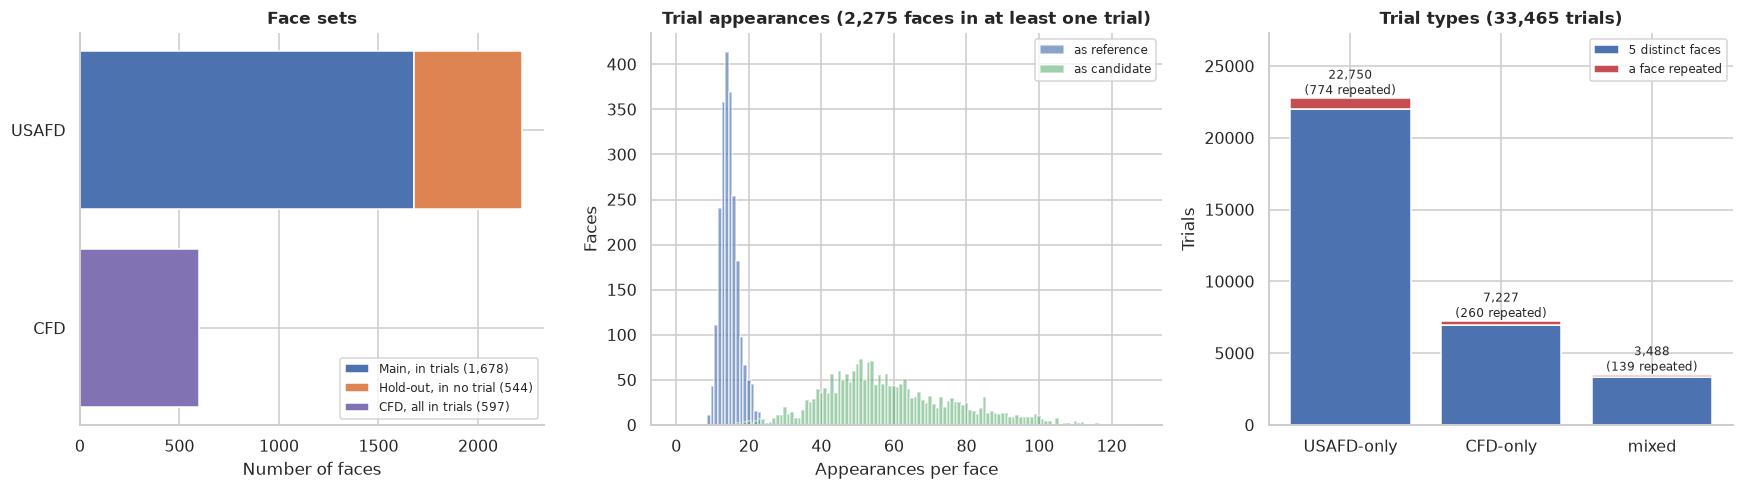

appearances per face: reference median 14, candidate median 56; trials with a repeated face: 1,173


In [19]:
# ---- Figure A. Face sets and trial structure ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1.1, 1]))

# A1: face sets
ax = axes[0]
ax.barh(["USAFD", "CFD"], [len(main), 0], color=SET_COLORS["main"], label=f"Main, in trials ({len(main):,})")
ax.barh(["USAFD", "CFD"], [len(hold), 0], left=[len(main), 0], color=SET_COLORS["holdout"],
        label=f"Hold-out, in no trial ({len(hold):,})")
ax.barh(["USAFD", "CFD"], [0, len(cfd)], color=SET_COLORS["cfd"], label=f"CFD, all in trials ({len(cfd):,})")
ax.invert_yaxis()
ax.set_xlabel("Number of faces")
ax.set_title("Face sets")
ax.legend(loc="lower right", fontsize=8, frameon=True)

# A2: appearances per face
ref_counts = np.bincount(trials[:, 0], minlength=N_TOTAL)
cand_counts = np.bincount(trials[:, 1:].ravel(), minlength=N_TOTAL)
used = (ref_counts + cand_counts) > 0
ax = axes[1]
bins = np.arange(0, max(ref_counts.max(), cand_counts.max()) + 2) - 0.5
ax.hist(ref_counts[used], bins=bins, alpha=0.65, color="#4C72B0", label="as reference")
ax.hist(cand_counts[used], bins=bins, alpha=0.55, color="#55A868", label="as candidate")
ax.set_xlabel("Appearances per face")
ax.set_ylabel("Faces")
ax.set_title(f"Trial appearances ({used.sum():,} faces in at least one trial)")
ax.legend(fontsize=8)

# A3: trial types, with trials that repeat a face
ax = axes[2]
order = ["usafd_only", "cfd_only", "mixed"]
n_by_type = tt.reindex(order).fillna(0).astype(int)
n_dup_by_type = pd.Series(n_unique < 5).groupby(ttype).sum().reindex(order).fillna(0).astype(int)
ax.bar(order, n_by_type - n_dup_by_type, color="#4C72B0", label="5 distinct faces")
ax.bar(order, n_dup_by_type, bottom=n_by_type - n_dup_by_type, color="#C44E52", label="a face repeated")
for i, (n, d) in enumerate(zip(n_by_type, n_dup_by_type)):
    ax.text(i, n, f"{n:,}\n({d:,} repeated)", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, n_by_type.max() * 1.2)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(["USAFD-only", "CFD-only", "mixed"])
ax.set_ylabel("Trials")
ax.set_title(f"Trial types ({len(trials):,} trials)")
ax.legend(fontsize=8, loc="upper right")

plt.tight_layout()
save(fig, "A_face_sets_trials")
plt.show()
print(f"appearances per face: reference median {int(np.median(ref_counts[used]))}, "
      f"candidate median {int(np.median(cand_counts[used]))}; "
      f"trials with a repeated face: {int((n_unique < 5).sum()):,}")


**Reading the figure**

- Faces appear as the reference a median of 14 times and as a candidate a median of 56 times. The spread is narrow, so no single face dominates the alignment scores.
- Trials with a repeated face: 774 USAFD-only, 260 CFD-only, 139 mixed (1,173 in total).

### Figure B. Human alignment by model

- **Left:** mean alignment with a 95% CI. The CI comes from a **cluster bootstrap over reference faces**: trials that share a reference face are resampled together because they are not independent. Overlapping CIs mean two models cannot be told apart on this task.
- **Middle:** alignment on USAFD-only vs CFD-only trials for each model.
- **Right:** the full distribution of per-trial ρ. With 4 candidates, ρ only takes the values −1, −0.8, …, 1. A mean of about 0.2 comes from a broad spread with many disagreements, not from consistently weak agreement.

CIs are written to `alignment_ci.csv`.

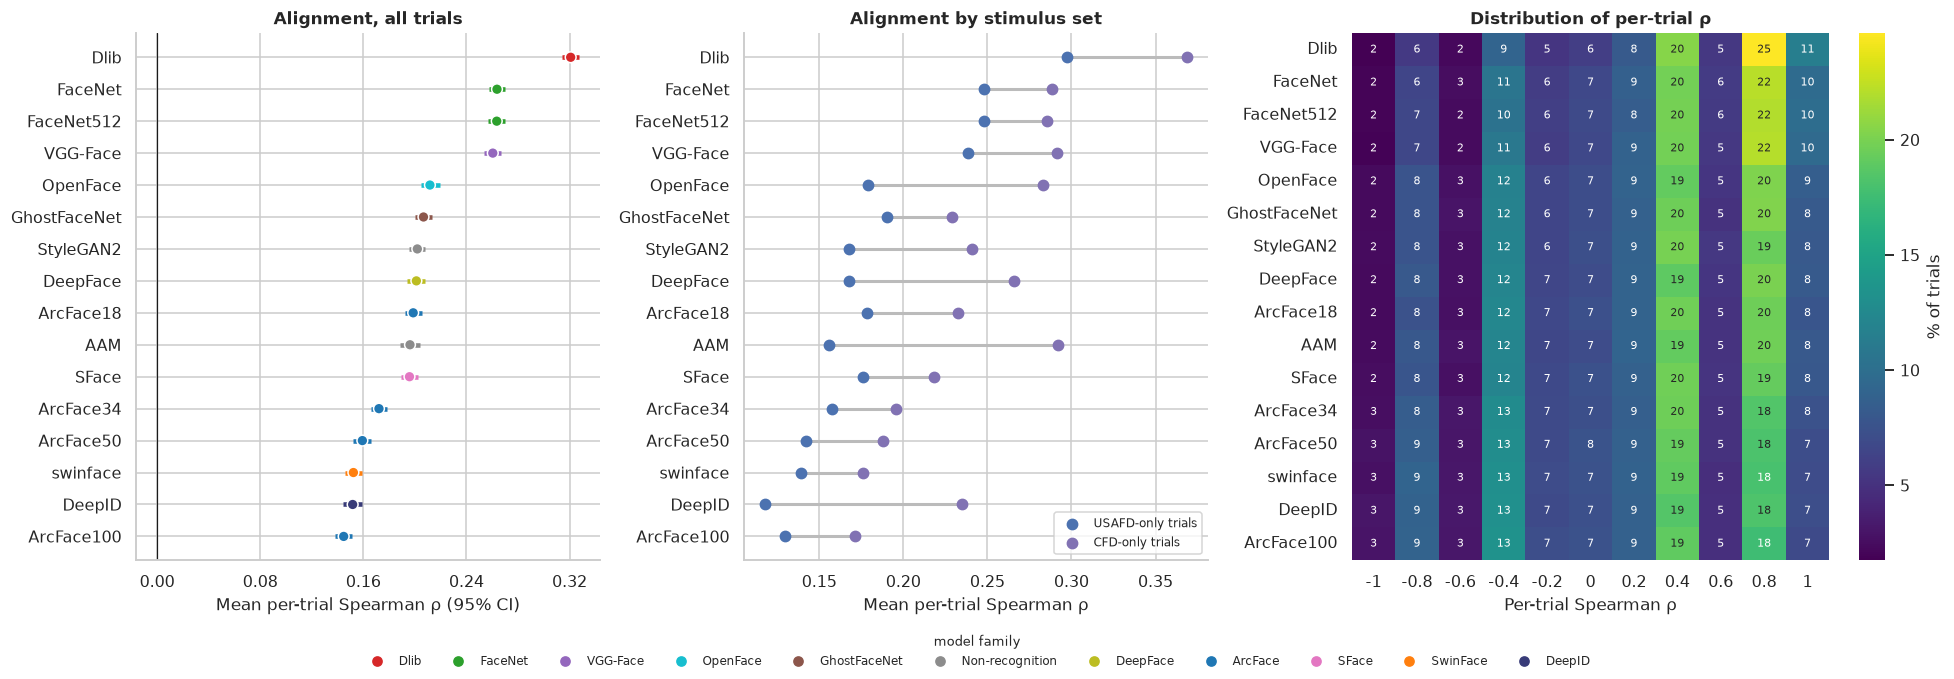

       model          family  mean    lo    hi
        Dlib            Dlib 0.321 0.314 0.327
     FaceNet         FaceNet 0.264 0.257 0.270
  FaceNet512         FaceNet 0.263 0.257 0.270
    VGG-Face        VGG-Face 0.260 0.254 0.267
    OpenFace        OpenFace 0.212 0.205 0.219
GhostFaceNet    GhostFaceNet 0.207 0.200 0.213
   StyleGAN2 Non-recognition 0.202 0.195 0.208
    DeepFace        DeepFace 0.201 0.194 0.208
   ArcFace18         ArcFace 0.199 0.192 0.205
         AAM Non-recognition 0.196 0.189 0.204
       SFace           SFace 0.196 0.189 0.202
   ArcFace34         ArcFace 0.172 0.166 0.178
   ArcFace50         ArcFace 0.159 0.152 0.166
    swinface        SwinFace 0.152 0.146 0.159
      DeepID          DeepID 0.152 0.144 0.159
  ArcFace100         ArcFace 0.145 0.138 0.151


In [20]:
# ---- Figure B. Human alignment by model ----
# 95% CI by cluster bootstrap over reference faces: trials that share a reference
# face are resampled together.  Multinomial weights give each bootstrap sample
# in one matrix product.
from matplotlib.lines import Line2D

N_BOOT = 2000
rng_b = np.random.default_rng(SEED)
uniq_ref, ref_inv = np.unique(trials[:, 0], return_inverse=True)
W = rng_b.multinomial(len(uniq_ref), np.full(len(uniq_ref), 1 / len(uniq_ref)), size=N_BOOT)

ci_rows = []
for name, (rs, ok) in per_trial.items():
    for split in ("all", "usafd", "cfd"):
        sel = ok & masks[split]
        S = np.bincount(ref_inv[sel], weights=rs[sel], minlength=len(uniq_ref))
        n = np.bincount(ref_inv[sel], minlength=len(uniq_ref)).astype(float)
        boot = (W @ S) / np.maximum(W @ n, 1)
        ci_rows.append(dict(model=name, family=FAMILY[name], split=split,
                            mean=S.sum() / n.sum(), lo=np.percentile(boot, 2.5),
                            hi=np.percentile(boot, 97.5), n_trials=int(sel.sum())))
al_ci = pd.DataFrame(ci_rows)
al_ci.to_csv(os.path.join(OUT, "alignment_ci.csv"), index=False)

a = al_ci[al_ci["split"] == "all"].sort_values("mean").reset_index(drop=True)
y = np.arange(len(a))
colors = [FAMILY_COLORS[f] for f in a["family"]]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), gridspec_kw=dict(width_ratios=[1.05, 1.05, 1.35]))

# B1: mean alignment with CI
ax = axes[0]
ax.hlines(y, a["lo"], a["hi"], color=colors, lw=3)
ax.scatter(a["mean"], y, color=colors, s=50, zorder=3, edgecolor="white")
ax.set_yticks(y)
ax.set_yticklabels(a["model"])
ax.axvline(0, color="k", lw=0.8)
ax.xaxis.set_major_locator(plt.MaxNLocator(5))
ax.set_xlabel("Mean per-trial Spearman ρ (95% CI)")
ax.set_title("Alignment, all trials")
fams = list(dict.fromkeys(a["family"][::-1]))
fam_handles = [Line2D([0], [0], marker="o", lw=0, color=FAMILY_COLORS[f], label=f) for f in fams]

# B2: USAFD-only vs CFD-only
ax = axes[1]
w = al_ci.pivot(index="model", columns="split", values="mean").loc[a["model"]]
ax.hlines(y, w["usafd"], w["cfd"], color="#bbbbbb", lw=2)
ax.scatter(w["usafd"], y, color=SET_COLORS["main"], s=45, zorder=3, label="USAFD-only trials")
ax.scatter(w["cfd"], y, color=SET_COLORS["cfd"], s=45, zorder=3, label="CFD-only trials")
ax.set_yticks(y)
ax.set_yticklabels(a["model"])
ax.set_xlabel("Mean per-trial Spearman ρ")
ax.set_title("Alignment by stimulus set")
ax.legend(fontsize=8, loc="lower right")

# B3: distribution of per-trial rho
ax = axes[2]
dist = pd.DataFrame({m: pd.Series(np.round(rs[ok], 2)).value_counts(normalize=True)
                     for m, (rs, ok) in per_trial.items()}).fillna(0).sort_index()
dist = dist[a["model"]]
sns.heatmap(dist.T * 100, cmap="viridis", ax=ax, annot=True, fmt=".0f", annot_kws={"size": 7},
            xticklabels=[f"{v:g}" for v in dist.index], cbar_kws={"label": "% of trials"})
ax.invert_yaxis()
ax.set_xlabel("Per-trial Spearman ρ")
ax.set_ylabel("")
ax.set_title("Distribution of per-trial ρ")

plt.tight_layout(rect=(0, 0.06, 1, 1))
fig.legend(handles=fam_handles, loc="lower center", ncol=len(fam_handles), fontsize=8, frameon=False,
           title="model family", title_fontsize=8.5)
save(fig, "B_alignment")
plt.show()
print(a[["model", "family", "mean", "lo", "hi"]].iloc[::-1].round(3).to_string(index=False))


**Reading the figure**

- The 95% intervals are narrow, about ±0.007. Models whose means differ by more than about 0.015 can be told apart.
- Dlib (0.321) is clearly the most aligned. FaceNet, FaceNet512 and VGG-Face (about 0.26) cannot be separated from each other. ArcFace100, DeepID, SwinFace and ArcFace50 (0.145–0.159) are the least aligned.
- Every model aligns better on CFD-only than on USAFD-only trials. The gap is largest for AAM (0.156 → 0.292) and DeepID (0.118 → 0.235), and smallest for SwinFace and the ArcFace models (about 0.04).
- Per-trial ρ: the most common values are +0.4 and +0.8 (about 18–25% of trials each). The models differ mainly in how often they rank all four candidates exactly as people do (ρ = 1): 11% of trials for Dlib, 7% for ArcFace100.

### Figure C. Recognition accuracy

- **Left:** d′ with its identity-bootstrap 95% CI. This is the accuracy measure used against alignment.
- **Middle:** ROC curves on a log false-positive axis. A linear axis hides all differences among the strong models, because their curves sit in the top-left corner. Dotted lines mark FPR = 10⁻⁴ and 10⁻³.
- **Right:** true-positive rate at the two strict thresholds, with CIs.

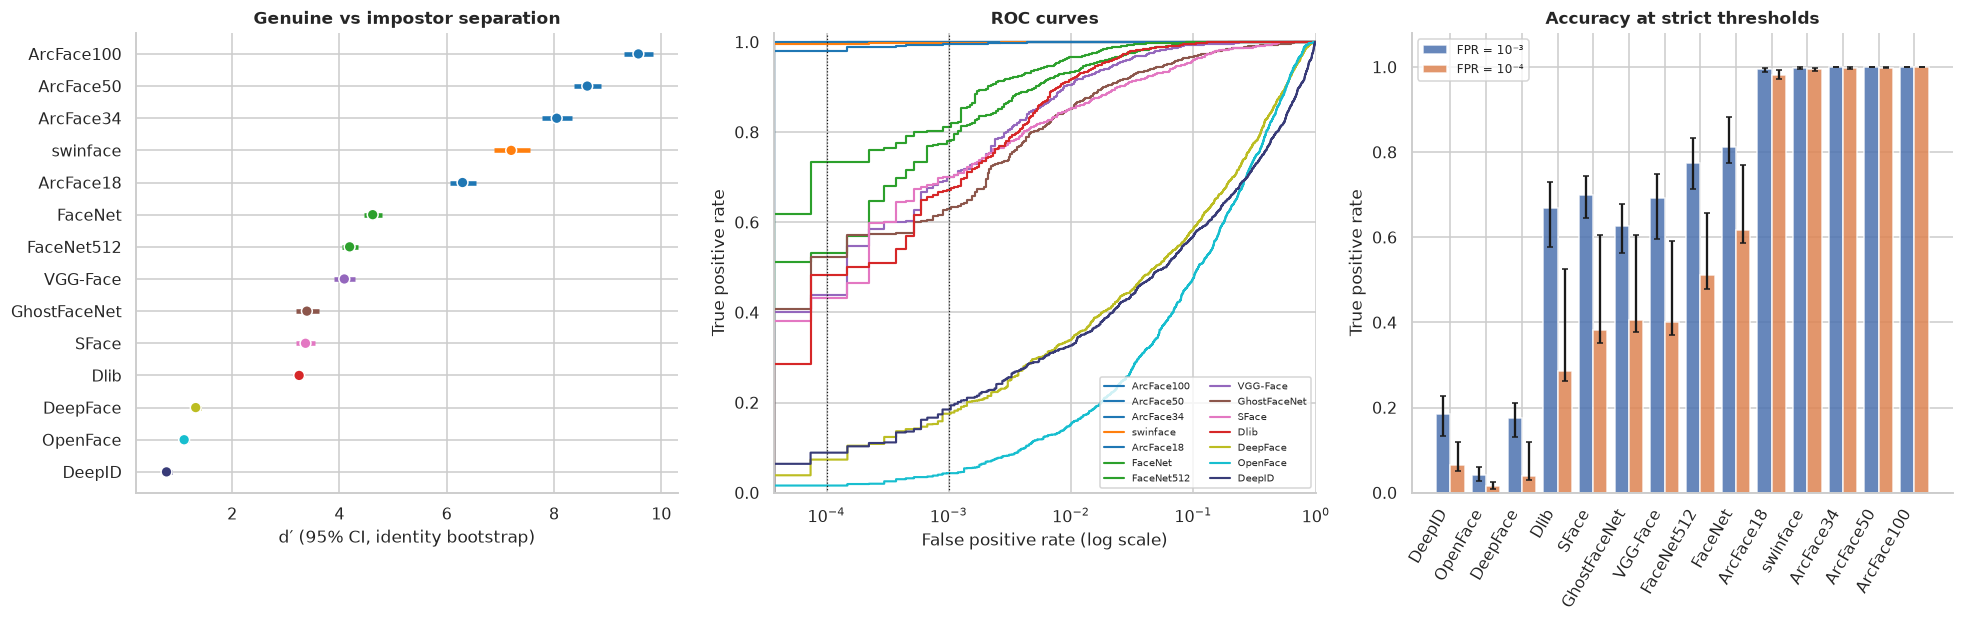

In [21]:
# ---- Figure C. Recognition accuracy ----
acc_k = acc.copy()
acc_k["family"] = acc_k["model_key"].map(FAMILY)
acc_k = acc_k.sort_values("dprime").reset_index(drop=True)
y = np.arange(len(acc_k))
colors = [FAMILY_COLORS[f] for f in acc_k["family"]]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))

# C1: d' with CI
ax = axes[0]
ax.hlines(y, acc_k["d_lo"], acc_k["d_hi"], color=colors, lw=3)
ax.scatter(acc_k["dprime"], y, color=colors, s=50, zorder=3, edgecolor="white")
ax.set_yticks(y)
ax.set_yticklabels(acc_k["model_key"])
ax.set_xlabel("d′ (95% CI, identity bootstrap)")
ax.set_title("Genuine vs impostor separation")

# C2: ROC curves on log-FPR axis
ax = axes[1]
floor = 1 / len(neg) / 2
for _, r in acc_k.iloc[::-1].iterrows():
    p_s, n_s = pair_scores[r["model"]]
    fpr, tpr, _ = roc_curve(np.r_[np.ones(len(p_s)), np.zeros(len(n_s))], np.r_[p_s, n_s])
    ax.plot(np.maximum(fpr, floor), tpr, color=FAMILY_COLORS[r["family"]], lw=1.4, label=r["model_key"])
ax.set_xscale("log")
ax.set_xlim(floor, 1)
ax.set_ylim(0, 1.02)
for f in (1e-4, 1e-3):
    ax.axvline(f, color="k", ls=":", lw=0.8)
ax.set_xlabel("False positive rate (log scale)")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves")
ax.legend(fontsize=6.5, ncol=2, loc="lower right")

# C3: TPR at strict thresholds
ax = axes[2]
x = np.arange(len(acc_k))
wbar = 0.4
for off, col, lo, hi, lab in ((-wbar / 2, "tpr_1e3", "tpr3_lo", "tpr3_hi", "FPR = 10⁻³"),
                              (wbar / 2, "tpr_1e4", "tpr4_lo", "tpr4_hi", "FPR = 10⁻⁴")):
    err = np.clip(np.vstack([acc_k[col] - acc_k[lo], acc_k[hi] - acc_k[col]]), 0, None)
    ax.bar(x + off, acc_k[col], wbar, yerr=err, capsize=2, label=lab, alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(acc_k["model_key"], rotation=60, ha="right")
ax.set_ylim(0, 1.08)
ax.set_ylabel("True positive rate")
ax.set_title("Accuracy at strict thresholds")
ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
save(fig, "C_recognition_accuracy")
plt.show()


**Reading the figure**

- The ArcFace models and SwinFace accept almost every genuine pair even at FPR = 10⁻⁴.
- In the middle group, d′ and the strict-threshold rates disagree. Dlib has a higher AUC than VGG-Face but accepts fewer genuine pairs at 10⁻⁴ (0.29 vs 0.40). This is why d′ and TPR are reported next to AUC.
- DeepFace, OpenFace and DeepID stay below 0.2 even at FPR = 10⁻³.

### Figure D. Alignment vs recognition accuracy

Each point is one model, with 95% CIs on both axes. The dashed line connects the four ArcFace depths: the same architecture and training data, only depth changes. Grey dotted lines mark the two non-recognition baselines, which have no recognition accuracy.

The Spearman ρ in the title is **descriptive only**. The models are not independent samples: several share architecture or training data.

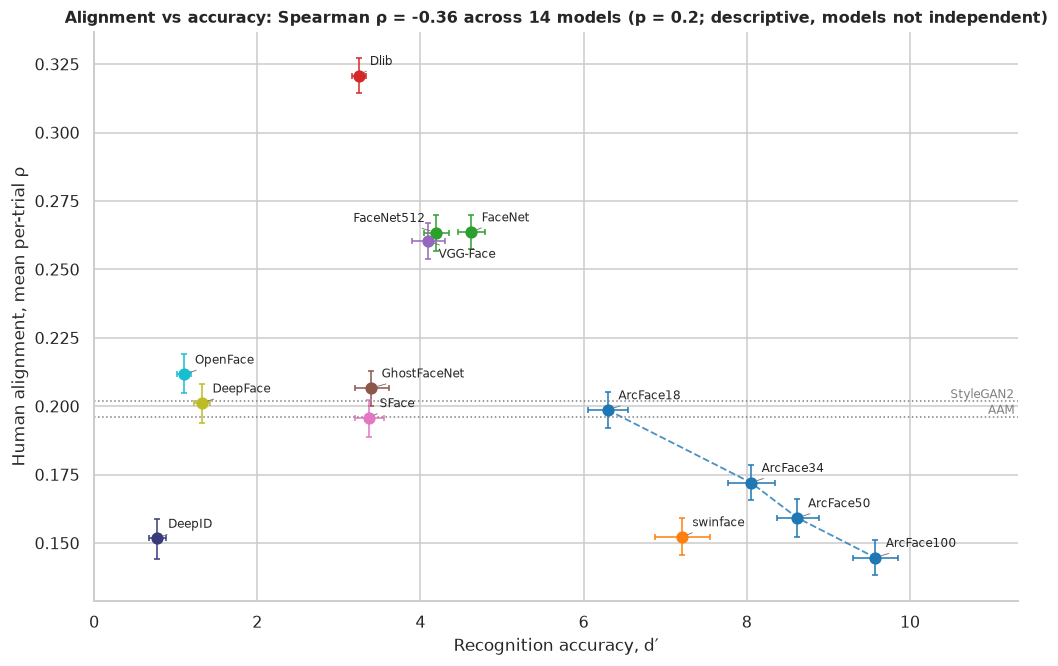

In [22]:
# ---- Figure D. Alignment vs recognition accuracy (model level) ----
def place_labels(ax, xs, ys, labels, fontsize=8):
    """Greedy label placement: try a few offsets per point, keep the first that overlaps nothing placed so far."""
    fig = ax.figure
    renderer = fig.canvas.get_renderer()
    cands = [(7, 5, "left", "bottom"), (7, -5, "left", "top"), (-7, 5, "right", "bottom"),
             (-7, -5, "right", "top"), (14, 14, "left", "bottom"), (14, -14, "left", "top"),
             (-14, 14, "right", "bottom"), (-14, -14, "right", "top"), (24, 0, "left", "center"),
             (-24, 0, "right", "center")]
    line = dict(arrowstyle="-", lw=0.6, color="#777777", shrinkA=0, shrinkB=4)
    placed = []
    pts = [ax.transData.transform((x, y)) for x, y in zip(xs, ys)]
    for x, y, lab in zip(xs, ys, labels):
        best = None
        for dx, dy, ha, va in cands:
            t = ax.annotate(lab, (x, y), xytext=(dx, dy), textcoords="offset points",
                            ha=ha, va=va, fontsize=fontsize, arrowprops=line)
            bb = t.get_window_extent(renderer=renderer).expanded(1.05, 1.2)
            hit = any(bb.overlaps(p) for p in placed) or any(bb.contains(px, py) for px, py in pts)
            if not hit:
                best = (t, bb)
                break
            t.remove()
        if best is None:   # nothing free: fall back to the first position
            dx, dy, ha, va = cands[0]
            t = ax.annotate(lab, (x, y), xytext=(dx, dy), textcoords="offset points",
                            ha=ha, va=va, fontsize=fontsize)
            best = (t, t.get_window_extent(renderer=renderer))
        placed.append(best[1])

m = acc[["model_key", "dprime", "d_lo", "d_hi"]].merge(
    al_ci[al_ci["split"] == "all"][["model", "family", "mean", "lo", "hi"]],
    left_on="model_key", right_on="model")
rho_d, p_d = spearmanr(m["dprime"], m["mean"])

fig, ax = plt.subplots(figsize=(9.5, 6.2))
for _, r in m.iterrows():
    c = FAMILY_COLORS[r["family"]]
    ax.errorbar(r["dprime"], r["mean"],
                xerr=[[r["dprime"] - r["d_lo"]], [r["d_hi"] - r["dprime"]]],
                yerr=[[r["mean"] - r["lo"]], [r["hi"] - r["mean"]]],
                fmt="o", color=c, ms=7, capsize=2, lw=1)
arc = m[m["family"] == "ArcFace"].sort_values("dprime")
ax.plot(arc["dprime"], arc["mean"], color=FAMILY_COLORS["ArcFace"], lw=1.2, ls="--", alpha=0.8)

xmax = m["d_hi"].max() * 1.15
ax.set_xlim(0, xmax)
for nm in NON_RECOG:
    v = al_ci[(al_ci["model"] == nm) & (al_ci["split"] == "all")]["mean"].iloc[0]
    ax.axhline(v, color="grey", ls=":", lw=1)
    ax.text(xmax, v, f"{nm} ", ha="right", va="bottom", fontsize=8, color="grey")
ax.set_xlabel("Recognition accuracy, d′")
ax.set_ylabel("Human alignment, mean per-trial ρ")
ax.set_title(f"Alignment vs accuracy: Spearman ρ = {rho_d:.2f} across {len(m)} models "
             f"(p = {p_d:.2g}; descriptive, models not independent)", fontsize=10.5)
plt.tight_layout()
fig.canvas.draw()
place_labels(ax, m["dprime"].to_numpy(), m["mean"].to_numpy(), m["model"].tolist())
save(fig, "D_alignment_vs_accuracy")
plt.show()


**Reading the figure**

- Across the 14 recognition models, Spearman ρ = −0.36 (p = 0.2). The relation is weak and not significant, and the models are not independent anyway.
- The clearest pattern is **within** one architecture. Along the ArcFace depths, alignment falls steadily as accuracy rises (0.199 → 0.145 while d′ goes 6.3 → 9.6). SwinFace, also highly accurate (d′ 7.2), is just as low (0.152).
- Outside that group there is no simple trade-off. The most aligned model, Dlib (0.321), has a middling d′ (3.25). FaceNet, FaceNet512 and VGG-Face sit at about 0.26 with d′ 4.1–4.6. Low accuracy does not bring high alignment: DeepID has the lowest d′ (0.78) and is among the least aligned (0.152).
- The two non-recognition models (0.196 and 0.202) align as well as several recognition models; they are shown for reference and are excluded from the thesis analysis.
- So the "more accurate, less human-like" claim is supported by a controlled comparison (the ArcFace depths) rather than by the cross-model correlation.

### Figure E. Fold contamination

For each outer fold, the test faces split into those never seen in that fold's training or validation trials (green) and those that were (red). The percentage of contaminated test faces is printed above each bar.

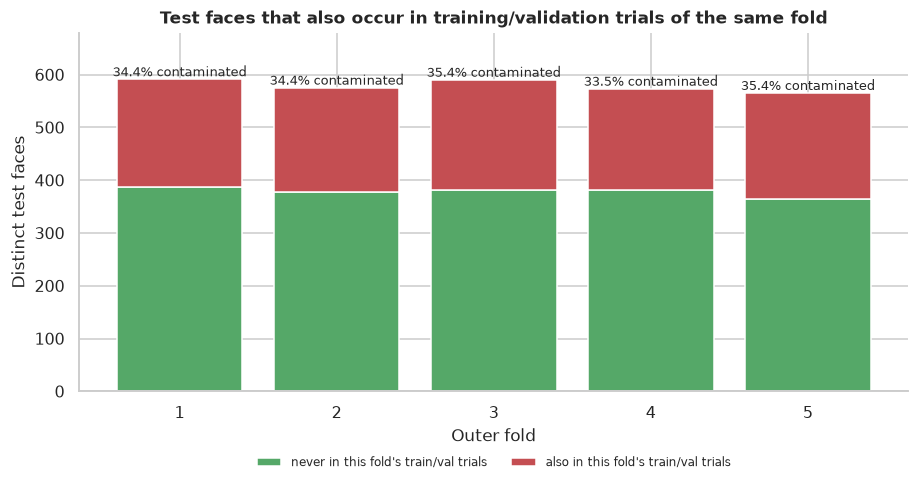

In [23]:
# ---- Figure E. Fold contamination ----
fig, ax = plt.subplots(figsize=(8.5, 4.6))
clean = leak["test_faces"] - leak["test_in_trainval_u10"]
ax.bar(leak["test_fold"], clean, color="#55A868", label="never in this fold's train/val trials")
ax.bar(leak["test_fold"], leak["test_in_trainval_u10"], bottom=clean, color="#C44E52",
       label="also in this fold's train/val trials")
for _, r in leak.iterrows():
    ax.text(r["test_fold"], r["test_faces"] + 6, f"{r['pct_u10']:.1f}% contaminated",
            ha="center", fontsize=8.5)
ax.set_ylim(0, leak["test_faces"].max() * 1.15)
ax.set_xticks(leak["test_fold"])
ax.set_xlabel("Outer fold")
ax.set_ylabel("Distinct test faces")
ax.set_title("Test faces that also occur in training/validation trials of the same fold")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
save(fig, "E_fold_contamination")
plt.show()


### Figure F. Trait scores and reliability

- **Left:** split-half reliability for all 20 traits. Filled dots use all raters; open dots drop rater 1236. Blue = the 14 core traits, orange = the others. The top axis converts reliability to the **highest correlation any predictor can reach** (√reliability).
- **Right:** distributions of the 14 core composite scores across the 2,222 faces, sorted by median.

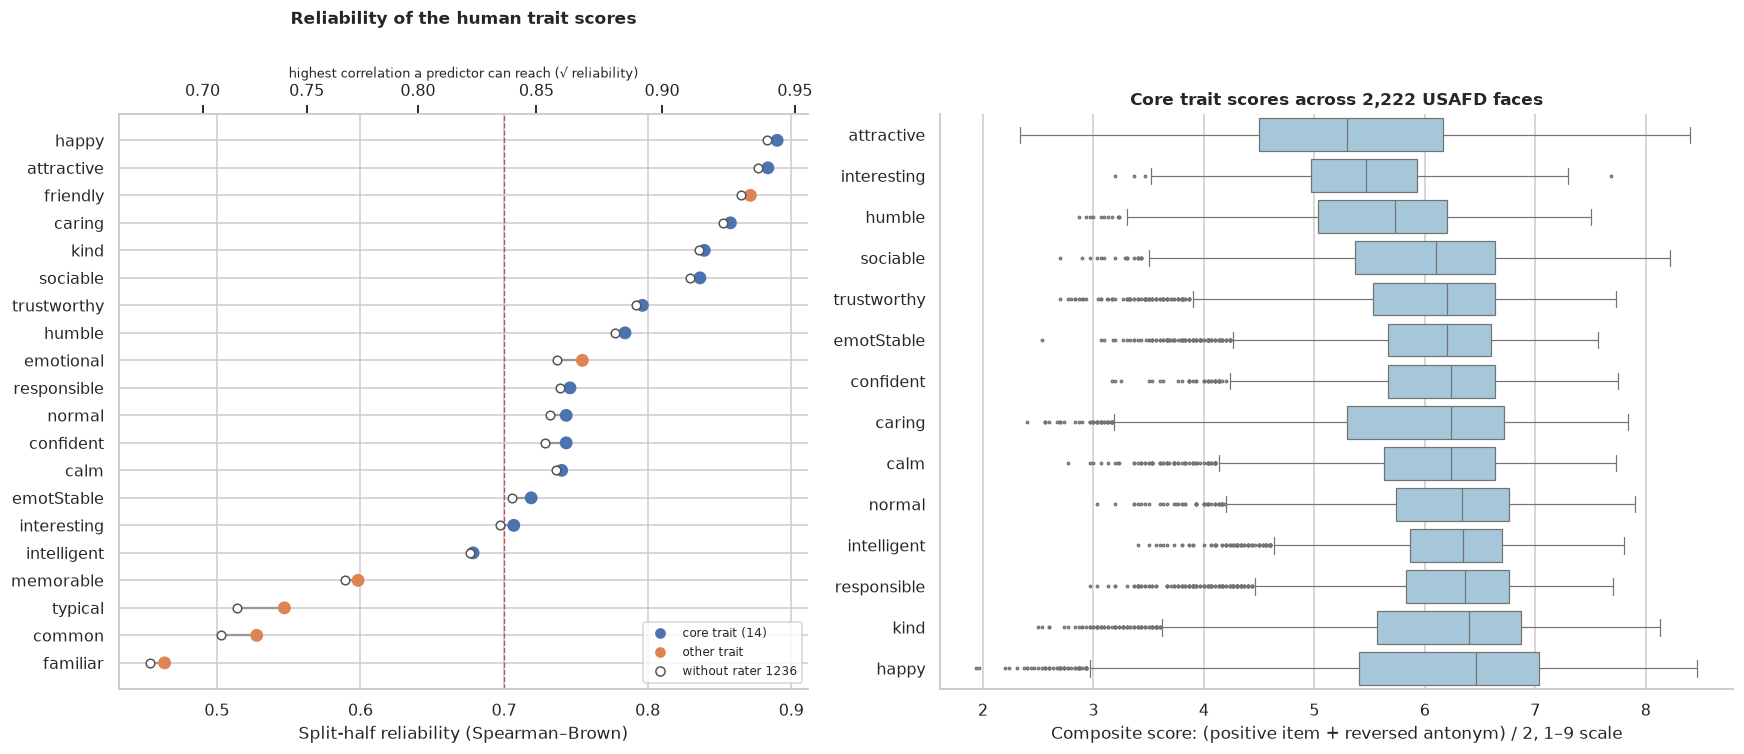

In [24]:
# ---- Figure F. Trait scores and reliability ----
r = rel_all.sort_values("sb_spearman_brown").reset_index(drop=True)
y = np.arange(len(r))
core = r["trait"].isin(TRAITS_14).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axes[0]
ax.hlines(y, r["sb_no1236"], r["sb_spearman_brown"], color="#999999", lw=1.5)
ax.scatter(r["sb_spearman_brown"], y, c=np.where(core, "#4C72B0", "#DD8452"), s=55, zorder=3)
ax.scatter(r["sb_no1236"], y, facecolor="white", edgecolor="#555555", s=32, zorder=3)
ax.axvline(0.7, color="#C44E52", ls="--", lw=0.9)
ax.set_yticks(y)
ax.set_yticklabels(r["trait"])
ax.set_xlabel("Split-half reliability (Spearman–Brown)")
ax.set_title("Reliability of the human trait scores", pad=28)
sec = ax.secondary_xaxis("top", functions=(lambda v: np.sqrt(np.clip(v, 0, None)), np.square))
sec.set_xlabel("highest correlation a predictor can reach (√ reliability)", fontsize=8.5)
ax.legend(handles=[Line2D([0], [0], marker="o", lw=0, color="#4C72B0", label="core trait (14)"),
                   Line2D([0], [0], marker="o", lw=0, color="#DD8452", label="other trait"),
                   Line2D([0], [0], marker="o", lw=0, markerfacecolor="white",
                          markeredgecolor="#555555", label="without rater 1236")],
          fontsize=8, loc="lower right")

ax = axes[1]
long = pool.melt(id_vars="label", value_vars=TRAITS_14, var_name="trait", value_name="score")
order = pool[TRAITS_14].median().sort_values().index.tolist()
sns.boxplot(data=long, y="trait", x="score", order=order, ax=ax, color="#9ecae1",
            fliersize=1.5, linewidth=0.8)
ax.set_xlabel("Composite score: (positive item + reversed antonym) / 2, 1–9 scale")
ax.set_ylabel("")
ax.set_title(f"Core trait scores across {len(pool):,} USAFD faces")

plt.tight_layout()
save(fig, "F_traits_reliability")
plt.show()


**Reading the figure**

- 13 of the 14 core traits are above 0.7. Only *intelligent* is below (0.68), and *interesting* (0.71) and *emotStable* (0.72) are just above. For a trait with reliability 0.74, no predictor can correlate above about 0.86 with the human scores.
- The four weakest traits (*memorable*, *typical*, *common*, *familiar*) are all outside the core set. Removing rater 1236 costs the most for *typical* and *common* (about 0.03) and very little for the core traits.
- Core trait medians lie between about 5.3 and 6.5 on the 1–9 scale. Faces are rated mildly positively on average, with long tails towards low scores.

### Figure G. Trait structure

- **Left:** correlations among the 14 core traits in the main set. Rows and columns are reordered by hierarchical clustering so that blocks of related traits sit together.
- **Middle:** main minus hold-out correlations, in the same order. Positive (orange) cells mean the pair correlates more strongly in the main set.
- **Right:** scree plot with the parallel-analysis 95th-percentile threshold for each set, on a log scale. Components above their dashed line are retained.

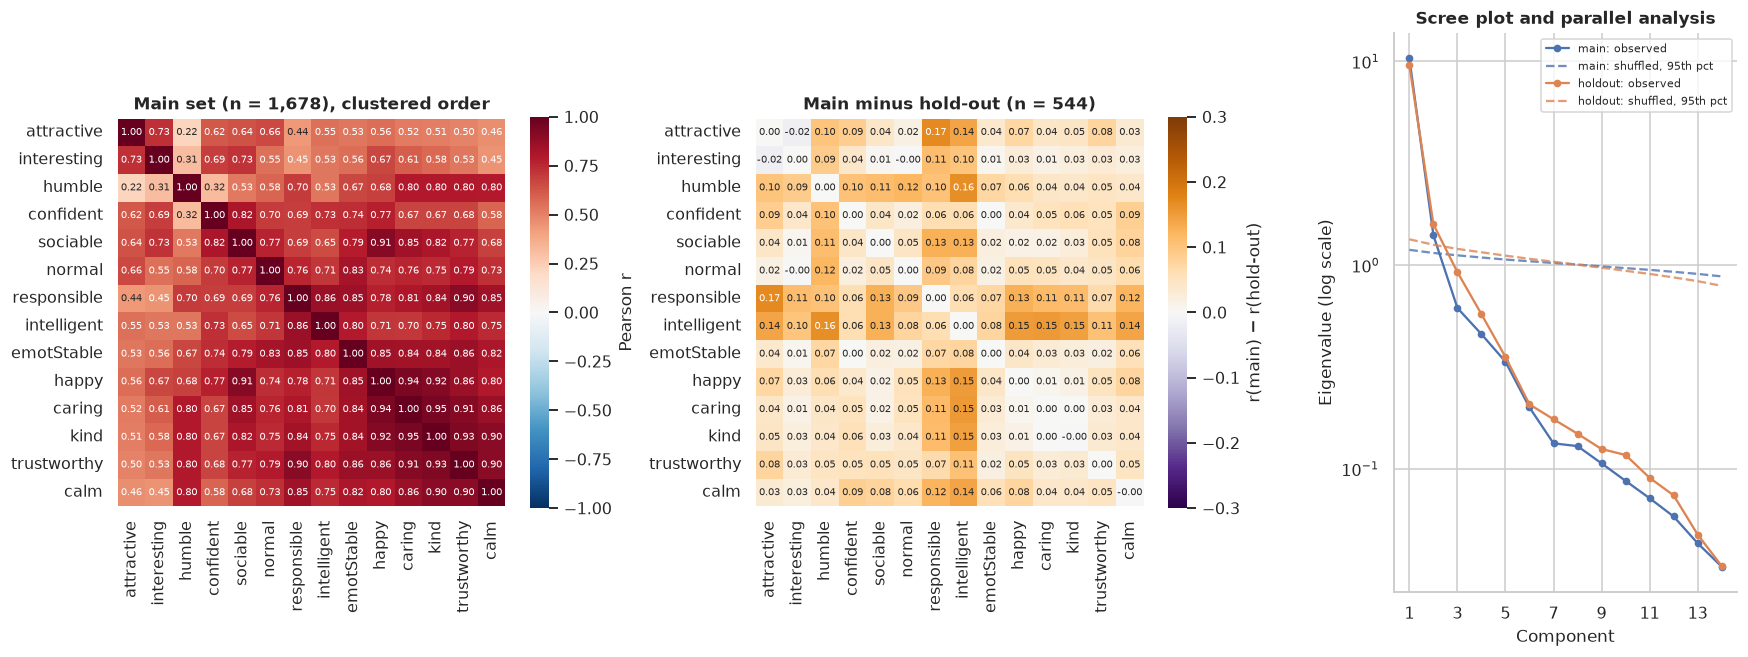

In [25]:
# ---- Figure G. Trait structure ----
from scipy.cluster.hierarchy import linkage, leaves_list

Rm, Rh = matrices["main"], matrices["holdout"]
order = leaves_list(linkage(squareform(1 - Rm, checks=False), method="average"))
names = [TRAITS_14[i] for i in order]

fig = plt.figure(figsize=(19, 6.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1.2, 0.85], wspace=0.35)

ax = fig.add_subplot(gs[0])
sns.heatmap(Rm[np.ix_(order, order)], ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            annot=True, fmt=".2f", annot_kws={"size": 6.5}, xticklabels=names, yticklabels=names,
            cbar_kws={"shrink": 0.7, "label": "Pearson r"})
ax.set_title(f"Main set (n = {len(main_ids):,}), clustered order")

ax = fig.add_subplot(gs[1])
sns.heatmap((Rm - Rh)[np.ix_(order, order)], ax=ax, cmap="PuOr_r", vmin=-0.3, vmax=0.3, center=0,
            square=True, annot=True, fmt=".2f", annot_kws={"size": 6.5},
            xticklabels=names, yticklabels=names,
            cbar_kws={"shrink": 0.7, "label": "r(main) − r(hold-out)"})
ax.set_title(f"Main minus hold-out (n = {len(hold_ids):,})")

ax = fig.add_subplot(gs[2])
for tag in ("main", "holdout"):
    s = scree[tag]
    k = np.arange(1, len(s["ev"]) + 1)
    ax.plot(k, s["ev"], "o-", color=SET_COLORS[tag], ms=4, label=f"{tag}: observed")
    ax.plot(k, s["null_p95"], "--", color=SET_COLORS[tag], alpha=0.8, label=f"{tag}: shuffled, 95th pct")
ax.set_yscale("log")
ax.set_xticks(range(1, len(TRAITS_14) + 1, 2))
ax.set_xlabel("Component")
ax.set_ylabel("Eigenvalue (log scale)")
ax.set_title("Scree plot and parallel analysis")
ax.legend(fontsize=7.5)

save(fig, "G_trait_structure")
plt.show()


**Reading the figure**

- Nearly every trait pair correlates above 0.5 in the main set. *Attractive*, *interesting* and *humble* are the most distinct traits. The warmth traits (*happy*, *caring*, *kind*, *trustworthy*, *calm*) correlate at 0.80–0.95.
- Main minus hold-out is positive in almost every cell, so the same trait pairs correlate more strongly in the main set. The largest differences (up to 0.17) involve *intelligent* and *responsible*.
- In both sets the first eigenvalue is about 10. The second is only just above the shuffled threshold, and the rest are below it.

### Figure H. Demographics: main vs hold-out

Percentages within each set, so sets of different sizes can be compared. Each panel title gives the chi-square test from section 11. Counts are printed above bars with fewer than 50 faces. A second panel shows the race × gender counts of the main set, the cells available for subgroup analyses.

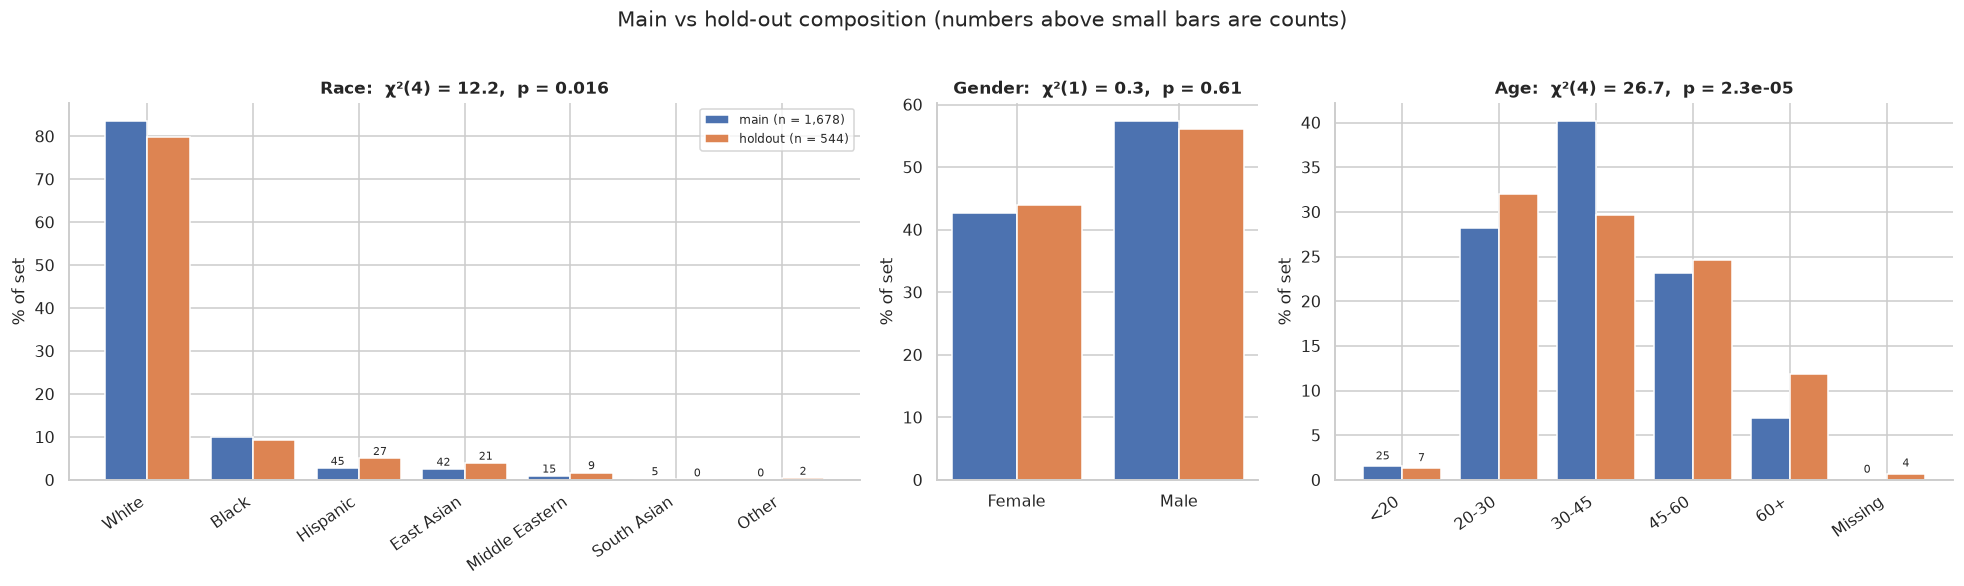

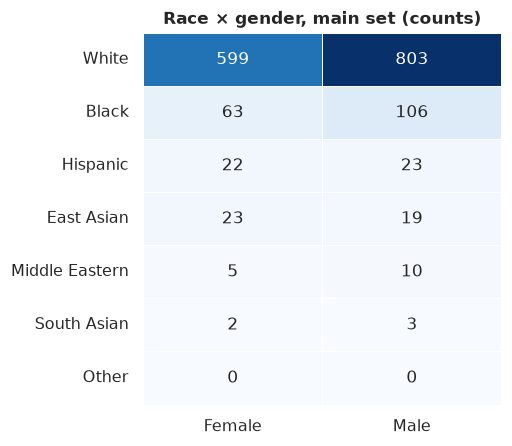

In [26]:
# ---- Figure H. Demographics: main vs hold-out ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw=dict(width_ratios=[1.6, 0.65, 1.25]))
for ax, (col, cats) in zip(axes, (("race", RACE_ORDER), ("gender", GENDER), ("age", AGE_ORDER))):
    sub = demo_table[demo_table["variable"] == col].set_index("category").loc[cats]
    x = np.arange(len(cats))
    wbar = 0.4
    for i, s in enumerate(("main", "holdout")):
        xs = x + (i - 0.5) * wbar
        ax.bar(xs, sub[f"{s}_pct"], wbar, color=SET_COLORS[s], label=f"{s} (n = {len(sets_map[s]):,})")
        for xi, pct, n in zip(xs, sub[f"{s}_pct"], sub[f"{s}_n"]):
            if n < 50:
                ax.text(xi, pct + 0.8, f"{n}", ha="center", fontsize=7)
    chi2, p, dof = demo_tests[col]
    ax.set_xticks(x)
    ax.set_xticklabels(cats, rotation=0 if col == "gender" else 35, ha="center" if col == "gender" else "right")
    ax.set_ylabel("% of set")
    ax.set_title(f"{col.capitalize()}:  χ²({dof}) = {chi2:.1f},  p = {p:.2g}")
axes[0].legend(fontsize=8)
fig.suptitle("Main vs hold-out composition (numbers above small bars are counts)", y=1.02)
plt.tight_layout()
save(fig, "H_demographics_main_vs_holdout")
plt.show()

fig, ax = plt.subplots(figsize=(4.8, 4.2))
sns.heatmap(rg_main, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, linewidths=0.5)
ax.set_title("Race × gender, main set (counts)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
save(fig, "H2_race_gender_main")
plt.show()


### Figure I. Memorability

- **Left:** distributions of hit and false-alarm rates, with the means reported by Bainbridge et al. (2013) as dotted lines.
- **Middle:** hit rate against false-alarm rate per face.
- **Right:** d′ distribution, with faces whose rates hit 0 or 1 (and were clipped) shown separately.

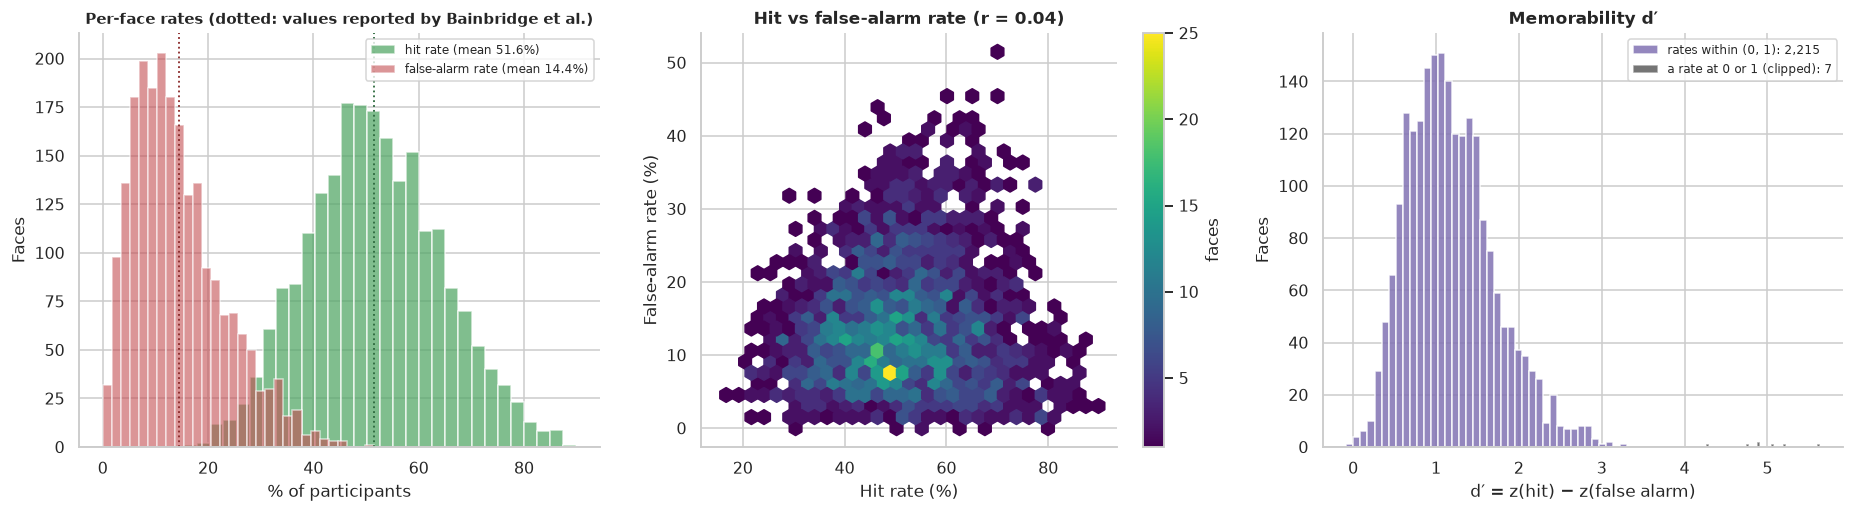

In [27]:
# ---- Figure I. Memorability ----
hr, far = mem["Hit Rate (HR)"], mem["False Alarm Rate (FAR)"]
clipped = ((hr <= 0) | (hr >= 1) | (far <= 0) | (far >= 1)).to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
ax.hist(hr * 100, bins=30, color="#55A868", alpha=0.75, label=f"hit rate (mean {hr.mean()*100:.1f}%)")
ax.hist(far * 100, bins=30, color="#C44E52", alpha=0.6, label=f"false-alarm rate (mean {far.mean()*100:.1f}%)")
ax.axvline(51.6, color="#2d6a3e", ls=":", lw=1.2)
ax.axvline(14.4, color="#8b2a2a", ls=":", lw=1.2)
ax.set_xlabel("% of participants")
ax.set_ylabel("Faces")
ax.set_title("Per-face rates (dotted: values reported by Bainbridge et al.)", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
hb = ax.hexbin(hr * 100, far * 100, gridsize=30, cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, label="faces")
ax.set_xlabel("Hit rate (%)")
ax.set_ylabel("False-alarm rate (%)")
ax.set_title(f"Hit vs false-alarm rate (r = {np.corrcoef(hr, far)[0, 1]:.2f})")

ax = axes[2]
ax.hist(mem.loc[~clipped, "d_prime"], bins=40, color="#8172B3", alpha=0.85,
        label=f"rates within (0, 1): {int((~clipped).sum()):,}")
if clipped.any():
    ax.hist(mem.loc[clipped, "d_prime"], bins=40, color="k", alpha=0.6,
            label=f"a rate at 0 or 1 (clipped): {int(clipped.sum()):,}")
ax.set_xlabel("d′ = z(hit) − z(false alarm)")
ax.set_ylabel("Faces")
ax.set_title("Memorability d′")
ax.legend(fontsize=8)

plt.tight_layout()
save(fig, "I_memorability")
plt.show()


### Figure J. CFD faces

- **Left:** self-reported race × gender counts.
- **Middle:** distributions of the three traits shared with Bainbridge. These ratings are on 1–7 and **relative to the same race and gender**.
- **Right:** rater-estimated age.

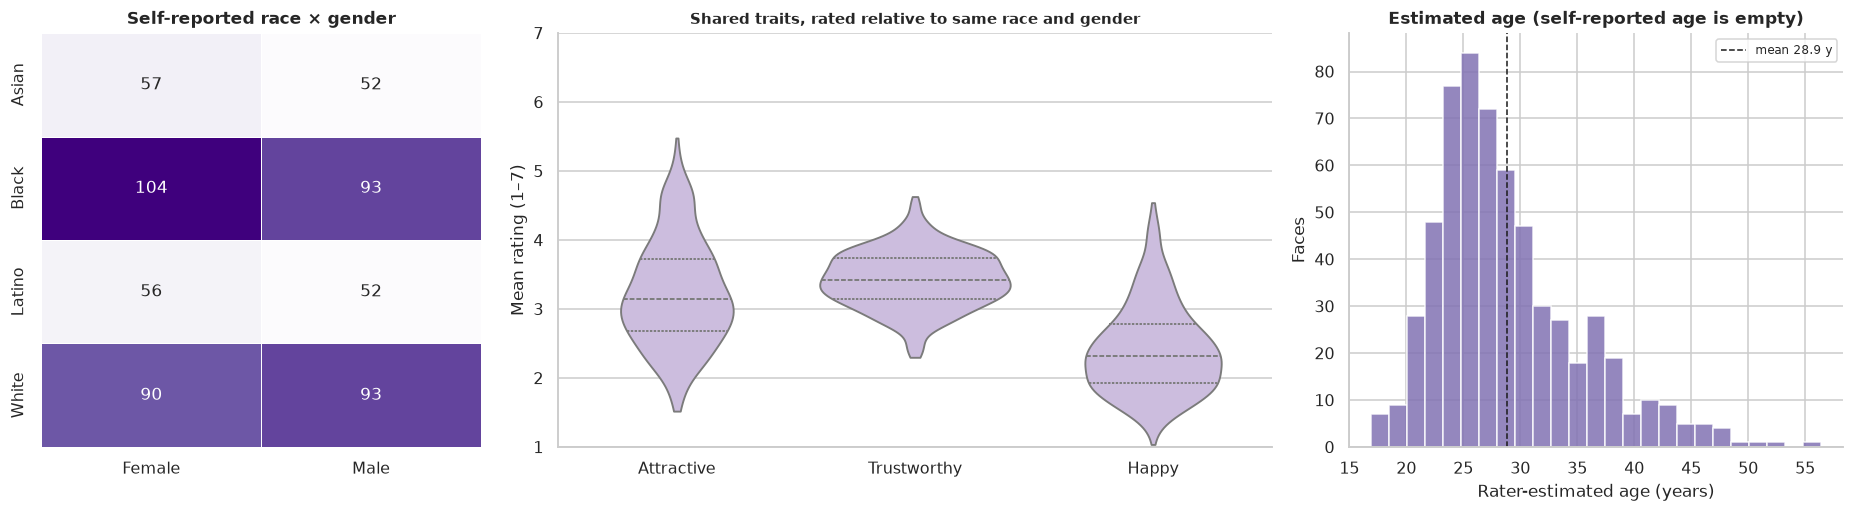

In [28]:
# ---- Figure J. CFD faces ----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[0.8, 1.3, 0.9]))

ax = axes[0]
ct = pd.crosstab(cfd_demo["race"], cfd_demo["gender"])
sns.heatmap(ct, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ax, linewidths=0.5)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Self-reported race × gender")

ax = axes[1]
shared = [s for s in SHARED if s in cfd_demo.columns]
long = cfd_demo.melt(value_vars=shared, var_name="trait", value_name="rating")
sns.violinplot(data=long, x="trait", y="rating", ax=ax, inner="quartile", cut=0, color="#cbb8e3")
ax.set_ylim(1, 7)
ax.set_xlabel("")
ax.set_ylabel("Mean rating (1–7)")
ax.set_title("Shared traits, rated relative to same race and gender", fontsize=10)

ax = axes[2]
ax.hist(cfd_demo["AgeRated"].dropna(), bins=25, color="#8172B3", alpha=0.85)
ax.axvline(cfd_demo["AgeRated"].mean(), color="k", ls="--", lw=1,
           label=f"mean {cfd_demo['AgeRated'].mean():.1f} y")
ax.set_xlabel("Rater-estimated age (years)")
ax.set_ylabel("Faces")
ax.set_title("Estimated age (self-reported age is empty)")
ax.legend(fontsize=8)

plt.tight_layout()
save(fig, "J_cfd")
plt.show()


### Figure K. Contact sheet (optional, local only)

Shows 8 random faces from each set with their labels, so you can check by eye that ids, sets and demographic labels line up. It is **off by default** (`SHOW_FACES = False`). The USAFD and CFD images are licensed, so the figure is never saved. If you switch it on, clear this cell's output before sharing the notebook. Set `USAFD_IMG_DIR` and `CFD_IMG_DIR` to the local image folders first.

In [29]:
# ---- Figure K. Contact sheet (optional, local only; never saved) ----
SHOW_FACES = False
USAFD_IMG_DIR = _walk(RAW, "usafd", "images_annotations")   # folder with the 10k US Adult Faces images
CFD_IMG_DIR = _walk(RAW, "cfd", "images_annotations")       # folder with the CFD images

def find_image(face_id):
    """Return the path of a face image, or None if it cannot be found."""
    if face_id <= N_USAFD:
        fname = str(face_id)
        cands = [os.path.join(USAFD_IMG_DIR, fname), os.path.join(USAFD_IMG_DIR, fname + ".jpg")]
    else:
        ident = str(face_id)
        cands = [os.path.join(CFD_IMG_DIR, ident + ".jpg")]
        d = os.path.join(CFD_IMG_DIR, ident)
        if os.path.isdir(d):   # CFD ships one folder per identity; prefer the neutral (-N) photo
            files = sorted(f for f in os.listdir(d) if f.lower().endswith((".jpg", ".png")))
            cands += [os.path.join(d, f) for f in files if "-N" in f] + [os.path.join(d, f) for f in files]
    return next((c for c in cands if os.path.exists(c)), None)

if not SHOW_FACES:
    print("Contact sheet skipped (SHOW_FACES = False). Face images are licensed and are not embedded here.")
else:
    rng_c = np.random.default_rng(SEED)
    sample_ids = np.r_[rng_c.choice(main, 8, replace=False), rng_c.choice(hold, 8, replace=False),
                       rng_c.choice(cfd, 8, replace=False)].astype(int)
    paths = {fid: find_image(fid) for fid in sample_ids}
    if not any(paths.values()):
        print(f"No images found. Checked:\n  {USAFD_IMG_DIR}\n  {CFD_IMG_DIR}\n"
              "Set USAFD_IMG_DIR and CFD_IMG_DIR to the local image folders.")
    else:
        main_set, cfd_lab = set(int(i) for i in main), cfd_demo.set_index("face_id")
        fig, axes = plt.subplots(3, 8, figsize=(18, 8.5))
        for ax, fid in zip(axes.ravel(), sample_ids):
            if paths[fid]:
                ax.imshow(plt.imread(paths[fid]))
            else:
                ax.text(0.5, 0.5, "not found", ha="center", va="center", transform=ax.transAxes)
            if fid <= N_USAFD:
                d = demo.loc[fid]
                lab, setname = f"{d['race']}, {d['gender']}, {d['age']}", ("Main" if fid in main_set else "Hold-out")
            else:
                d = cfd_lab.loc[fid]
                lab, setname = f"{d['race']}, {d['gender']}", "CFD"
            ax.set_title(f"{setname} #{fid}\n{lab}", fontsize=7.5)
            ax.axis("off")
        fig.suptitle("Rows: main, hold-out, CFD. Check that the labels match the faces.")
        plt.tight_layout()
        plt.show()   # deliberately not saved; clear this output before sharing


Contact sheet skipped (SHOW_FACES = False). Face images are licensed and are not embedded here.


### Figure L. Key numbers and check status

A one-table summary of the headline data facts, and the MATCH / MISMATCH / NEW count per section of the facts table.

                                 quantity                                       value
                        Similarity trials         33,465 (1,173 with a repeated face)
             Faces: main / hold-out / CFD                           1,678 / 544 / 597
            Alignment, recognition models          0.145 (ArcFace100) to 0.321 (Dlib)
               Alignment, AAM / StyleGAN2                               0.196 / 0.202
       Alignment reproduction, max |diff|                                     5.6e-17
                           Recognition d′                                0.78 to 9.57
                 Alignment vs d′ (models)                          Spearman ρ = -0.36
                       Fold contamination           33.5–35.4% of test faces per fold
              Reliability, 14 core traits                    mean 0.783 (0.678–0.890)
            PC1 variance, main / hold-out                               73.8% / 68.2%
Main vs hold-out (p): race / gender / age             

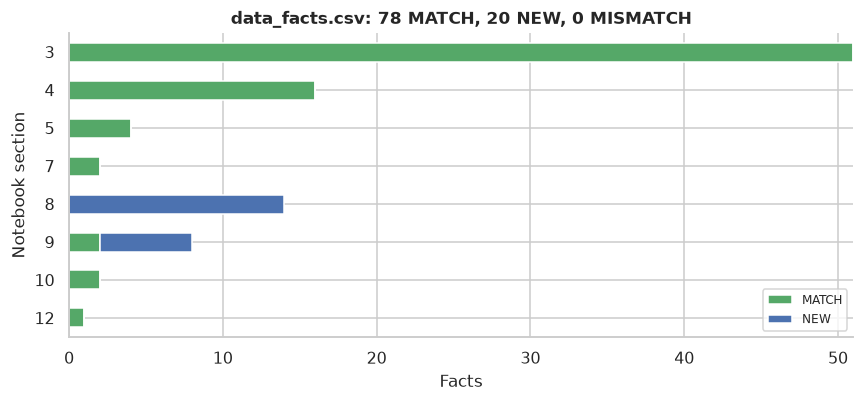

In [30]:
# ---- Figure L. Key numbers and check status ----
a_all = al_ci[al_ci["split"] == "all"].set_index("model")["mean"]
rec = a_all.drop(list(NON_RECOG))
key = pd.DataFrame([
    ("Similarity trials", f"{len(trials):,} ({int((n_unique < 5).sum()):,} with a repeated face)"),
    ("Faces: main / hold-out / CFD", f"{len(main):,} / {len(hold):,} / {len(cfd):,}"),
    ("Alignment, recognition models", f"{rec.min():.3f} ({rec.idxmin()}) to {rec.max():.3f} ({rec.idxmax()})"),
    ("Alignment, AAM / StyleGAN2", f"{a_all['AAM']:.3f} / {a_all['StyleGAN2']:.3f}"),
    ("Alignment reproduction, max |diff|", f"{al['maxdiff'].max():.1e}"),
    ("Recognition d′", f"{acc['dprime'].min():.2f} to {acc['dprime'].max():.2f}"),
    ("Alignment vs d′ (models)", f"Spearman ρ = {rho_d:.2f}"),
    ("Fold contamination", f"{leak['pct_u10'].min():.1f}–{leak['pct_u10'].max():.1f}% of test faces per fold"),
    ("Reliability, 14 core traits", f"mean {rel_14['sb_spearman_brown'].mean():.3f} "
                                     f"({rel_14['sb_spearman_brown'].min():.3f}–{rel_14['sb_spearman_brown'].max():.3f})"),
    ("PC1 variance, main / hold-out", f"{st.loc[st['set']=='main', 'var_share_factor1'].iloc[0]*100:.1f}% / "
                                       f"{st.loc[st['set']=='holdout', 'var_share_factor1'].iloc[0]*100:.1f}%"),
    ("Main vs hold-out (p): race / gender / age", " / ".join(f"{demo_tests[c][1]:.2g}" for c in ("race", "gender", "age"))),
    ("Memorability HR / FAR", f"{mem['Hit Rate (HR)'].mean()*100:.1f}% / {mem['False Alarm Rate (FAR)'].mean()*100:.1f}%"),
    ("CFD self-reported race", ", ".join(f"{k} {v}" for k, v in cfd_demo["race"].value_counts().items())),
], columns=["quantity", "value"])
key.to_csv(os.path.join(OUT, "key_numbers.csv"), index=False)
print(key.to_string(index=False))

status = facts_df.groupby(["section", "status"]).size().unstack(fill_value=0)
status = status.reindex(columns=[c for c in ("MATCH", "NEW", "MISMATCH") if c in status.columns])
fig, ax = plt.subplots(figsize=(8, 3.8))
status.plot(kind="barh", stacked=True, ax=ax,
            color=[{"MATCH": "#55A868", "NEW": "#4C72B0", "MISMATCH": "#C44E52"}[c] for c in status.columns])
ax.invert_yaxis()
ax.set_xlabel("Facts")
ax.set_ylabel("Notebook section")
ax.set_title(f"data_facts.csv: {int((facts_df.status == 'MATCH').sum())} MATCH, "
             f"{int((facts_df.status == 'NEW').sum())} NEW, {int((facts_df.status == 'MISMATCH').sum())} MISMATCH")
ax.legend(fontsize=8)
plt.tight_layout()
save(fig, "L_facts_status")
plt.show()
